# Top-10 motifs per level and a test of the song hierarchy (10-hour recording)

The original figure ("Top-10 motifs with all copies (length 70.0 s), SOCAL_H_76_230427_011115+014845.x.wav") shows
three panels for a 75-minute recording:

1. the MFCC coefficient 2 series (c1) with the copies of the top-10 motifs coloured, one colour per motif;
2. the MFCC energy c0 averaged over a sliding 10 s window, where dips below the 10th percentile are quiet periods;
3. a timeline with one row per motif, its copies drawn as rectangles and joined by a dotted line.

This notebook produces the same analysis for each level of humpback song (**unit, phrase, theme, song**) on the
whole 10-hour recording `SOCAL_H_76_230426_193500_df100.x.x.wav`, using one representative length per level from
Phase 1 ([report](reports/Phase1_Length_Range_Report.md)). It then tests the hypothesis behind the levels:
**a song contains themes, a theme contains phrases, a phrase contains units**. The plan is in
[`Motif_Hierarchy_Plan.md`](Motif_Hierarchy_Plan.md).

The original figure's recording (`011115+014845`, 75 min) lies inside the 10-hour file at **20,175–24,675 s**
(01:11:15–02:26:15 clock time), so every level is also shown on exactly that window. The last section draws every
copy of every motif on a **page-by-page 10-hour timeline** (saved as `reports/Motif_Hierarchy_Timeline.pdf`).

All figures are numbered and saved to `reports/figures/p3_*.png`; each one is followed by a caption cell that
explains how to read it and what it shows.

## Notation

| symbol | meaning |
|---|---|
| $x(t)$ | MFCC coefficient 2 (**c1**, column 2 of the feature matrix), block-averaged to the level's analysis rate |
| c0 | MFCC coefficient 1 (log energy of the mel spectrum); its 10 s moving average is the energy panel |
| $m$ | motif length in points: $m = \text{length (s)} \times \text{rate (Hz)}$ |
| $d$ | z-normalized Euclidean distance between two windows of length $m$ (the matrix profile value) |
| $r$ | Pearson correlation of two windows, $r = 1 - d^2 / (2m)$; $r = 1$ is a perfect match |
| $\theta$ | null threshold of a level: top-decile nearest-neighbour $r$ of a phase-randomized surrogate |
| **S**$k$, **T**$k$, **P**$k$, **U**$k$ | song, theme, phrase, unit motif number $k$ ($k = 1$ is found first: best match in the matrix profile) |
| copy $c_j$ | the $j$-th copy of a motif in time order; every copy has $r \ge \theta$ with the motif's seed |
| seed | the window a motif was grown from ($r = 1$ with itself); drawn with ▲ or a black outline |
| A ⊃ B | a copy of level B is *inside* a copy of level A if at least 90% of it overlaps |
| quiet | c0 10 s mean below its 10th percentile (grey shading) |
| time | hours since the start of the recording (2023-04-26 19:35:00) and clock time from the file timestamp |

Motif colours are shared by all levels: motif 1 is dark red, motif 10 dark blue (turbo colour map), so **T3** and
**P3** have the same colour; the letter and the row tell the levels apart.

In [1]:
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib.patches import Patch, Rectangle

import whale_mfcc as w

warnings.filterwarnings("ignore", category=RuntimeWarning)
plt.rcParams["figure.dpi"] = 100
plt.rcParams["pdf.fonttype"] = 42
pd.set_option("display.width", 160)

K = 10  # motifs per level
LEVELS = {  # representative length (s), analysis rate (Hz), null segments (count, seconds)
    "unit": dict(length_s=4.15, rate=20, segments=(8, 300), n_null=1),
    "phrase": dict(length_s=33, rate=10, segments=(3, 3600), n_null=1),
    "theme": dict(length_s=95, rate=2, segments=None, n_null=2),
    "song": dict(length_s=600, rate=1, segments=None, n_null=2),
}
ORDER = ["song", "theme", "phrase", "unit"]  # top to bottom of the hierarchy
LETTER = {"song": "S", "theme": "T", "phrase": "P", "unit": "U"}
IMAGE_WINDOW = (20175.0, 24675.0)  # SOCAL_H_76_230427_011115+014845 inside the 10 h file
COLORS = plt.cm.turbo(np.linspace(0.05, 0.95, K))[::-1]  # motif 1 dark red ... motif 10 dark blue
CLOCK0 = pd.Timestamp("2023-04-26 19:35:00")  # start of the 10 h file
FIG_DIR = os.path.join("reports", "figures")
os.makedirs(FIG_DIR, exist_ok=True)

C10, FRAME_RATE = w.load_or_compute_features(w.WAV_10H_PATH, "whale_mfcc_193500_100hz.npz")
DURATION = len(C10) / FRAME_RATE
SERIES = {lvl: w.block_average(C10[:, 2], int(round(FRAME_RATE / cfg["rate"]))) for lvl, cfg in LEVELS.items()}
ENERGY = w.rolling_mean(C10[:, 1], int(10 * FRAME_RATE))[:: int(FRAME_RATE)]  # c0, 10 s mean, 1 Hz
QUIET = np.nanpercentile(ENERGY, 10)
print(f"10 h recording: {DURATION / 3600:.2f} h; c0 10 s mean 10th percentile = {QUIET:.3f}")

10 h recording: 10.00 h; c0 10 s mean 10th percentile = -30.419


## Settings

| level | length | rate | m (points) | why this length |
|---|---|---|---|---|
| unit | 4.15 s | 20 Hz | 83 | peak of the unit bump in Phase 1 (c1) |
| phrase | 33 s | 10 Hz | 330 | most frequent phrase length in Phase 2 |
| theme | 95 s | 2 Hz | 190 | peak of the excess repetition (c1) |
| song | 600 s | 1 Hz | 600 | most regular copies (one per ~13 min song cycle) |

Units are analysed at 20 Hz instead of 100 Hz: a matrix profile of all 3.6 million 100 Hz frames would take hours.

**Top-k motifs with all copies.** The matrix profile of c1 (exclusion zone = the full length) is computed once
per level. Motif 1's seed is the window with the best match; its **copies are all windows whose correlation with the
seed reaches the null threshold**, taken greedily without overlap. Those copies are blanked, and motif 2 is
searched among the remaining windows, and so on. Copies of different motifs of one level therefore never overlap,
as in the original figure. The threshold is the top-decile nearest-neighbour correlation of a phase-randomized
surrogate (same spectrum, no repeated shapes) at the level's length and rate: a copy must be at least as similar as
the best 10% of chance matches.

In [2]:
TOP = {}
for level, cfg in LEVELS.items():
    TOP[level] = w.level_top_motifs(C10, FRAME_RATE, level, k=K, **cfg).reset_index(drop=True)
SEEDS = {lvl: tab.loc[tab.groupby("motif")["r"].idxmax()].set_index("motif") for lvl, tab in TOP.items()}

rows = []
for level in ORDER:
    tab, cfg = TOP[level], LEVELS[level]
    counts = tab.groupby("motif").size()
    rows.append({
        "level": level, "length (s)": cfg["length_s"], "rate (Hz)": cfg["rate"],
        "m": int(round(cfg["length_s"] * cfg["rate"])),
        "threshold r": round(tab["threshold"].iloc[0], 3), "motifs": len(counts),
        "copies": len(tab), "copies per motif": ", ".join(map(str, counts.tolist())),
        "median copy r": round(tab["r"][tab["r"] < 1].median(), 3),
        "night covered": f"{(tab['length_s'].sum() / DURATION):.0%}",
    })
pd.DataFrame(rows).set_index("level")

,length (s),rate (Hz),m,threshold r,motifs,copies,copies per motif,median copy r,night covered
level,,,,,,,,,
song,600.00,1,600,0.592,2,9,"7, 2",0.667,15%
theme,95.00,2,190,0.566,10,117,"21, 17, 18, 11, 14, 7, 2, 6, 19, 2",0.639,31%
phrase,33.00,10,330,0.577,10,263,"77, 58, 62, 45, 4, 2, 5, 4, 3, 3",0.654,24%
unit,4.15,20,83,0.821,10,1157,"650, 14, 182, 91, 35, 132, 4, 4, 13, 32",0.858,13%


**Table 1. Motifs found per level.** *m*: motif length in points; *threshold r*: the null threshold θ every copy
must reach; *copies per motif*: S1, S2, … in order; *median copy r*: median correlation of the copies with their
seed (seeds excluded); *night covered*: total duration of all copies divided by the 10 hours.

In [3]:
def clock(s, fmt="%H:%M"):
    return (CLOCK0 + pd.to_timedelta(float(s), unit="s")).strftime(fmt)


def fmt_gap(s):
    if not np.isfinite(s):
        return "–"
    return f"{s:.0f} s" if s < 120 else f"{s / 60:.0f} min"


def motif_stats(level):
    tab, rows = TOP[level], []
    for mi, c in tab.groupby("motif"):
        s = np.sort(c["start_s"].to_numpy())
        seed = SEEDS[level].loc[mi]
        in_win = (c["start_s"] + c["length_s"] >= IMAGE_WINDOW[0]) & (c["start_s"] <= IMAGE_WINDOW[1])
        rows.append({
            "motif": f"{LETTER[level]}{mi}", "copies": len(c),
            "median r": round(c["r"][c["r"] < 1].median(), 3) if len(c) > 1 else np.nan,
            "min r": round(c["r"].min(), 3),
            "seed": f"{clock(seed['start_s'], '%H:%M:%S')} ({seed['start_s'] / 3600:.2f} h)",
            "first": f"{s[0] / 3600:.2f} h", "last": f"{s[-1] / 3600:.2f} h",
            "median gap": fmt_gap(np.median(np.diff(s)) if len(s) > 1 else np.nan),
            "in image window": int(in_win.sum()),
            "time covered": f"{c['length_s'].sum() / 60:.1f} min",
        })
    return pd.DataFrame(rows).set_index("motif")


STATS = {lvl: motif_stats(lvl) for lvl in ORDER}


def show(fig, name):
    fig.savefig(os.path.join(FIG_DIR, f"p3_{name}.png"), dpi=110, bbox_inches="tight")
    plt.show()


def nice_step(span_s, n=10):
    steps = [10, 30, 60, 120, 300, 600, 900, 1800, 3600, 7200]
    return next((s for s in steps if span_s / s <= n), steps[-1])


def clock_ticks(t0, t1, step):
    off = (CLOCK0 - CLOCK0.normalize()).total_seconds()
    first = np.ceil((t0 + off) / step) * step - off
    return np.arange(first, t1 + 1e-9, step)


def add_clock_axis(ax, t0, t1, X):
    step = nice_step(t1 - t0)
    ticks = clock_ticks(t0, t1, step)
    top = ax.secondary_xaxis("top")
    top.set_ticks(X(ticks), labels=[clock(s, "%H:%M" if step >= 60 else "%H:%M:%S") for s in ticks])
    top.tick_params(labelsize=8)
    top.set_xlabel("clock time (file timestamp)", fontsize=8)


def runs(mask, offset=0):
    q = np.r_[False, mask, False]
    edges = np.flatnonzero(np.diff(q.astype(int)))
    return [(offset + a, offset + b) for a, b in zip(edges[::2], edges[1::2])]


def quiet_runs(t0, t1, level=None):
    i0, i1 = int(t0), int(min(t1, len(ENERGY)))
    return runs(ENERGY[i0:i1] < (QUIET if level is None else level), i0)


def envelope(t, x, n_bins=5000):
    b = max(1, len(x) // n_bins)
    if b == 1:
        return t, x, x, 1
    k = len(x) // b
    xs = x[: k * b].reshape(k, b)
    return t[: k * b : b], np.nanmin(xs, axis=1), np.nanmax(xs, axis=1), b


def in_view(tab, t0, t1):
    return tab[(tab["start_s"] + tab["length_s"] >= t0) & (tab["start_s"] <= t1)]


def busiest_window(level, span_s, t0, t1):
    starts = TOP[level]["start_s"].to_numpy()
    starts = starts[(starts >= t0) & (starts <= t1 - span_s)]
    best = max(starts, key=lambda s: np.sum((starts >= s) & (starts < s + span_s)))
    return best, best + span_s


for level in ORDER:
    print(level)
    display(STATS[level])

song


,copies,median r,min r,seed,first,last,median gap,in image window,time covered
motif,,,,,,,,,
S1,7,0.643,0.601,00:24:06 (4.82 h),4.82 h,8.84 h,36 min,4,70.0 min
S2,2,0.832,0.663,21:25:03 (1.83 h),1.83 h,2.07 h,14 min,0,20.0 min


theme


,copies,median r,min r,seed,first,last,median gap,in image window,time covered
motif,,,,,,,,,
T1,21,0.667,0.580,21:59:47 (2.41 h),1.07 h,9.36 h,17 min,4,33.2 min
T2,17,0.622,0.573,22:03:12 (2.47 h),0.51 h,7.72 h,16 min,1,26.9 min
T3,18,0.685,0.568,22:16:36 (2.69 h),1.82 h,9.41 h,13 min,3,28.5 min
T4,11,0.641,0.576,02:37:34 (7.04 h),0.84 h,8.79 h,49 min,1,17.4 min
T5,14,0.653,0.572,21:22:27 (1.79 h),0.90 h,9.57 h,21 min,4,22.2 min
T6,7,0.594,0.575,01:38:30 (6.06 h),1.71 h,8.64 h,27 min,3,11.1 min
T7,2,0.663,0.663,21:47:17 (2.20 h),2.20 h,2.92 h,43 min,0,3.2 min
T8,6,0.648,0.581,02:49:01 (7.23 h),1.14 h,8.21 h,64 min,0,9.5 min
T9,19,0.610,0.575,00:29:28 (4.91 h),0.24 h,9.67 h,27 min,6,30.1 min


phrase


,copies,median r,min r,seed,first,last,median gap,in image window,time covered
motif,,,,,,,,,
P1,77,0.626,0.579,20:29:58 (0.92 h),0.51 h,9.59 h,4 min,15,42.4 min
P2,58,0.665,0.582,22:00:37 (2.43 h),0.19 h,9.37 h,7 min,7,31.9 min
P3,62,0.668,0.578,22:22:26 (2.79 h),0.66 h,9.61 h,9 min,6,34.1 min
P4,45,0.668,0.578,20:17:07 (0.70 h),0.45 h,9.49 h,10 min,7,24.8 min
P5,4,0.694,0.602,21:23:59 (1.82 h),1.82 h,6.65 h,58 min,2,2.2 min
P6,2,0.813,0.626,01:14:02 (5.65 h),4.49 h,5.65 h,70 min,1,1.1 min
P7,5,0.590,0.587,00:21:27 (4.77 h),4.04 h,5.20 h,13 min,0,2.8 min
P8,4,0.630,0.599,22:20:43 (2.76 h),2.76 h,7.66 h,83 min,0,2.2 min
P9,3,0.598,0.580,23:51:55 (4.28 h),4.28 h,8.22 h,118 min,1,1.6 min


unit


,copies,median r,min r,seed,first,last,median gap,in image window,time covered
motif,,,,,,,,,
U1,650,0.869,0.821,21:24:00 (1.82 h),0.41 h,9.59 h,12 s,104,45.0 min
U2,14,0.841,0.831,00:46:45 (5.20 h),4.48 h,5.65 h,36 s,1,1.0 min
U3,182,0.851,0.821,21:50:56 (2.27 h),0.38 h,9.78 h,45 s,15,12.6 min
U4,91,0.841,0.822,20:31:11 (0.94 h),0.51 h,9.62 h,3 min,12,6.3 min
U5,35,0.859,0.821,01:02:44 (5.46 h),2.80 h,6.87 h,19 s,0,2.4 min
U6,132,0.852,0.822,00:19:02 (4.73 h),0.53 h,9.81 h,95 s,15,9.1 min
U7,4,0.838,0.833,21:22:40 (1.79 h),1.79 h,9.19 h,137 min,0,0.3 min
U8,4,0.857,0.826,00:49:14 (5.24 h),5.24 h,5.96 h,8 min,1,0.3 min
U9,13,0.847,0.828,00:59:13 (5.40 h),4.60 h,5.47 h,21 s,0,0.9 min


**Table 2. Every motif of every level.** *median r* / *min r*: correlation of the copies with the seed (seed
excluded from the median); *seed*: where the motif was found (clock time and hours since 19:35); *first* / *last*:
first and last copy (hours since 19:35); *median gap*: median time between consecutive copy starts; *in image
window*: copies overlapping the original figure's 75 minutes; *time covered*: total duration of the copies.

## Image-style figures per level

For each level: the whole night (time in hours), then the original figure's 75-minute window (time in seconds from
its start, as in the original), and for units and phrases a short zoom where individual copies can be seen. Each
figure has the three panels of the original:

- **(a)** the c1 series in grey with each copy coloured by its motif; ▲ marks the seed of each motif; the box under
  the legend gives the motif length *m*, the threshold θ and the number of copies;
- **(b)** c0 energy (10 s moving average) with the 10th percentile **of the plotted span** (dashed red, as in the
  original) and the windows below it shaded grey;
- **(c)** one row per motif: rectangles are copies (true length; very short ones are widened to stay visible), the
  dotted line joins copies of the same motif, the seed has a black outline, and the text on the right gives the
  number of copies in view / in total and the median gap between copies.

On whole-night views the c1 series is drawn as its min–max envelope and the original figure's window is shaded
yellow. The clock time is on the top axis.

In [4]:
def plot_level(level, t0, t1, hours=False, title="", name=None):
    cfg, tab, T = LEVELS[level], TOP[level], SERIES[level]
    let, rate = LETTER[level], cfg["rate"]
    m, thr = int(round(cfg["length_s"] * rate)), tab["threshold"].iloc[0]
    scale, origin = (3600.0, 0.0) if hours else (1.0, t0)
    X = lambda s: (np.asarray(s, dtype=float) - origin) / scale
    i0, i1 = int(t0 * rate), int(min(t1 * rate, len(T)))
    t = np.arange(i0, i1) / rate
    tt, lo, hi, b = envelope(t, T[i0:i1])
    bw = b / rate
    motifs = sorted(tab["motif"].unique())
    view = in_view(tab, t0, t1)
    show_window = hours and IMAGE_WINDOW[1] > t0 and IMAGE_WINDOW[0] < t1

    fig, axes = plt.subplots(3, 1, figsize=(16, 12.5), gridspec_kw=dict(height_ratios=[2.3, 1.2, 1.9]))
    fig.suptitle(title, fontsize=13, fontweight="bold")

    ax = axes[0]
    if b == 1:
        ax.plot(X(tt), lo, c="0.65", lw=0.5, label="c1 series")
    else:
        ax.bar(X(tt), hi - lo, bottom=lo, width=bw / scale, align="edge", color="0.7", lw=0,
               label="c1 series (min–max)")
    for mi in motifs:
        cps = tab[tab["motif"] == mi]
        st = STATS[level].loc[f"{let}{mi}"]
        color, labelled = COLORS[mi - 1], False
        for a, L in zip(cps["start_s"], cps["length_s"]):
            if a + L < t0 or a > t1:
                continue
            lab = None if labelled else f"{let}{mi}: {len(cps)} copies, median r {st['median r']:.2f}"
            labelled = True
            if b == 1:
                j0, j1 = max(i0, int(a * rate)), min(i1, int((a + L) * rate))
                ax.plot(X(np.arange(j0, j1) / rate), T[j0:j1], c=color, lw=0.8, label=lab)
            else:
                idx = np.flatnonzero((tt + bw > a) & (tt < a + L))
                if not len(idx):
                    idx = [int(np.clip(np.searchsorted(tt, a) - 1, 0, len(tt) - 1))]
                ax.bar(X(tt[idx]), (hi - lo)[idx], bottom=lo[idx], width=bw / scale, align="edge",
                       color=color, lw=0, label=lab)
    last_mid, tier = -np.inf, 0
    for mi, s in SEEDS[level].sort_values("start_s").iterrows():
        mid = s["start_s"] + s["length_s"] / 2
        if t0 <= mid <= t1:
            tier = (tier + 1) % 3 if mid - last_mid < (t1 - t0) / 40 else 0
            last_mid = mid
            ax.plot(X(mid), 0.03, marker="^", ms=9, color=COLORS[mi - 1], mec="k", mew=0.6,
                    transform=ax.get_xaxis_transform(), clip_on=False, zorder=5)
            ax.text(X(mid), 0.07 + 0.045 * tier, f"{let}{mi}", transform=ax.get_xaxis_transform(), ha="center",
                    fontsize=7)
    if show_window:
        for a in axes:
            a.axvspan(X(IMAGE_WINDOW[0]), X(IMAGE_WINDOW[1]), color="gold", alpha=0.18, lw=0, zorder=0)
        ax.text(X(np.mean(IMAGE_WINDOW)), 0.98, "original figure\nwindow", transform=ax.get_xaxis_transform(),
                ha="center", va="top", fontsize=8, color="0.3")
    ax.set_xlim(X(t0), X(t1))
    ax.set_ylabel("c1 = MFCC coefficient 2")
    ax.set_title(f"(a) c1 with the copies of the {len(motifs)} {level} motifs coloured "
                 f"({let}1 dark red … {let}{len(motifs)} blue); ▲ = seed of each motif", loc="left", fontsize=10)
    ax.legend(loc="upper left", bbox_to_anchor=(1.005, 1), fontsize=8, title=f"{level} motifs", title_fontsize=8)
    info = (f"m = {m} points = {cfg['length_s']:g} s at {rate} Hz\n"
            f"copy rule: r ≥ θ = {thr:.3f} (null threshold)\n"
            f"{len(motifs)} motifs, {len(tab)} copies,\n{len(view)} of them in this view\n"
            f"copies cover {tab['length_s'].sum() / DURATION:.0%} of the night")
    ax.text(1.005, 0.0, info, transform=ax.transAxes, ha="left", va="bottom", fontsize=8,
            bbox=dict(boxstyle="round", fc="w", ec="0.6"))
    add_clock_axis(ax, t0, t1, X)

    ax = axes[1]
    e0, e1 = int(t0), int(min(t1, len(ENERGY)))
    q = np.nanpercentile(ENERGY[e0:e1], 10)
    for k, (a, c) in enumerate(quiet_runs(t0, t1, q)):
        ax.axvspan(X(a), X(c), color="0.82", lw=0, zorder=0, label="below 10th percentile (quiet)" if k == 0 else None)
    ax.plot(X(np.arange(e0, e1)), ENERGY[e0:e1], c="k", lw=0.6, label="c0, 10 s moving average")
    ax.axhline(q, c="r", ls="--", lw=1, label=f"10th percentile of this view = {q:.1f}")
    ax.set_xlim(X(t0), X(t1))
    ax.set_ylabel("c0 (10 s mean)")
    ax.set_title("(b) MFCC energy (c0) in a sliding 10 s window: dips are quiet periods", loc="left", fontsize=10)
    ax.legend(loc="upper left", bbox_to_anchor=(1.005, 1), fontsize=8)
    ax.grid(alpha=0.3)

    ax = axes[2]
    min_w = (t1 - t0) / scale / 400
    for k, mi in enumerate(motifs):
        y = len(motifs) - 1 - k
        cps = tab[tab["motif"] == mi]
        inside = in_view(cps, t0, t1)
        seed = SEEDS[level].loc[mi]
        if len(inside) > 1:
            ax.plot([X(inside["start_s"].min()), X(inside["start_s"].max())], [y, y], ":",
                    c=COLORS[mi - 1], lw=0.8)
        for a, L in zip(inside["start_s"], inside["length_s"]):
            is_seed = a == seed["start_s"]
            ax.add_patch(Rectangle((X(a), y - 0.3), max(L / scale, min_w), 0.6, fc=COLORS[mi - 1],
                                   ec="k" if is_seed else "none", lw=1.2 if is_seed else 0, zorder=3 if is_seed else 2))
        gap = STATS[level].loc[f"{let}{mi}", "median gap"]
        ax.text(1.005, y, f"{len(inside)} here / {len(cps)} total, median gap {gap}",
                transform=ax.get_yaxis_transform(), va="center", fontsize=8)
    ax.set_yticks(range(len(motifs)))
    ax.set_yticklabels([f"{let}{mi}" for mi in motifs][::-1])
    ax.set_ylim(-0.7, len(motifs) - 0.3)
    ax.set_xlim(X(t0), X(t1))
    ax.set_ylabel("motif")
    ax.set_title("(c) Timeline of the copies: rectangle = copy, dotted line joins copies of one motif, "
                 "black outline = seed", loc="left", fontsize=10)
    ax.set_xlabel("time since the start of the recording, 2023-04-26 19:35:00 (h)" if hours else
                  f"time (s) from {clock(t0, '%H:%M:%S')} (= {t0:,.0f} s into the recording)")
    ax.grid(alpha=0.3)
    fig.tight_layout()
    show(fig, name or level)

### Units (4.15 s)

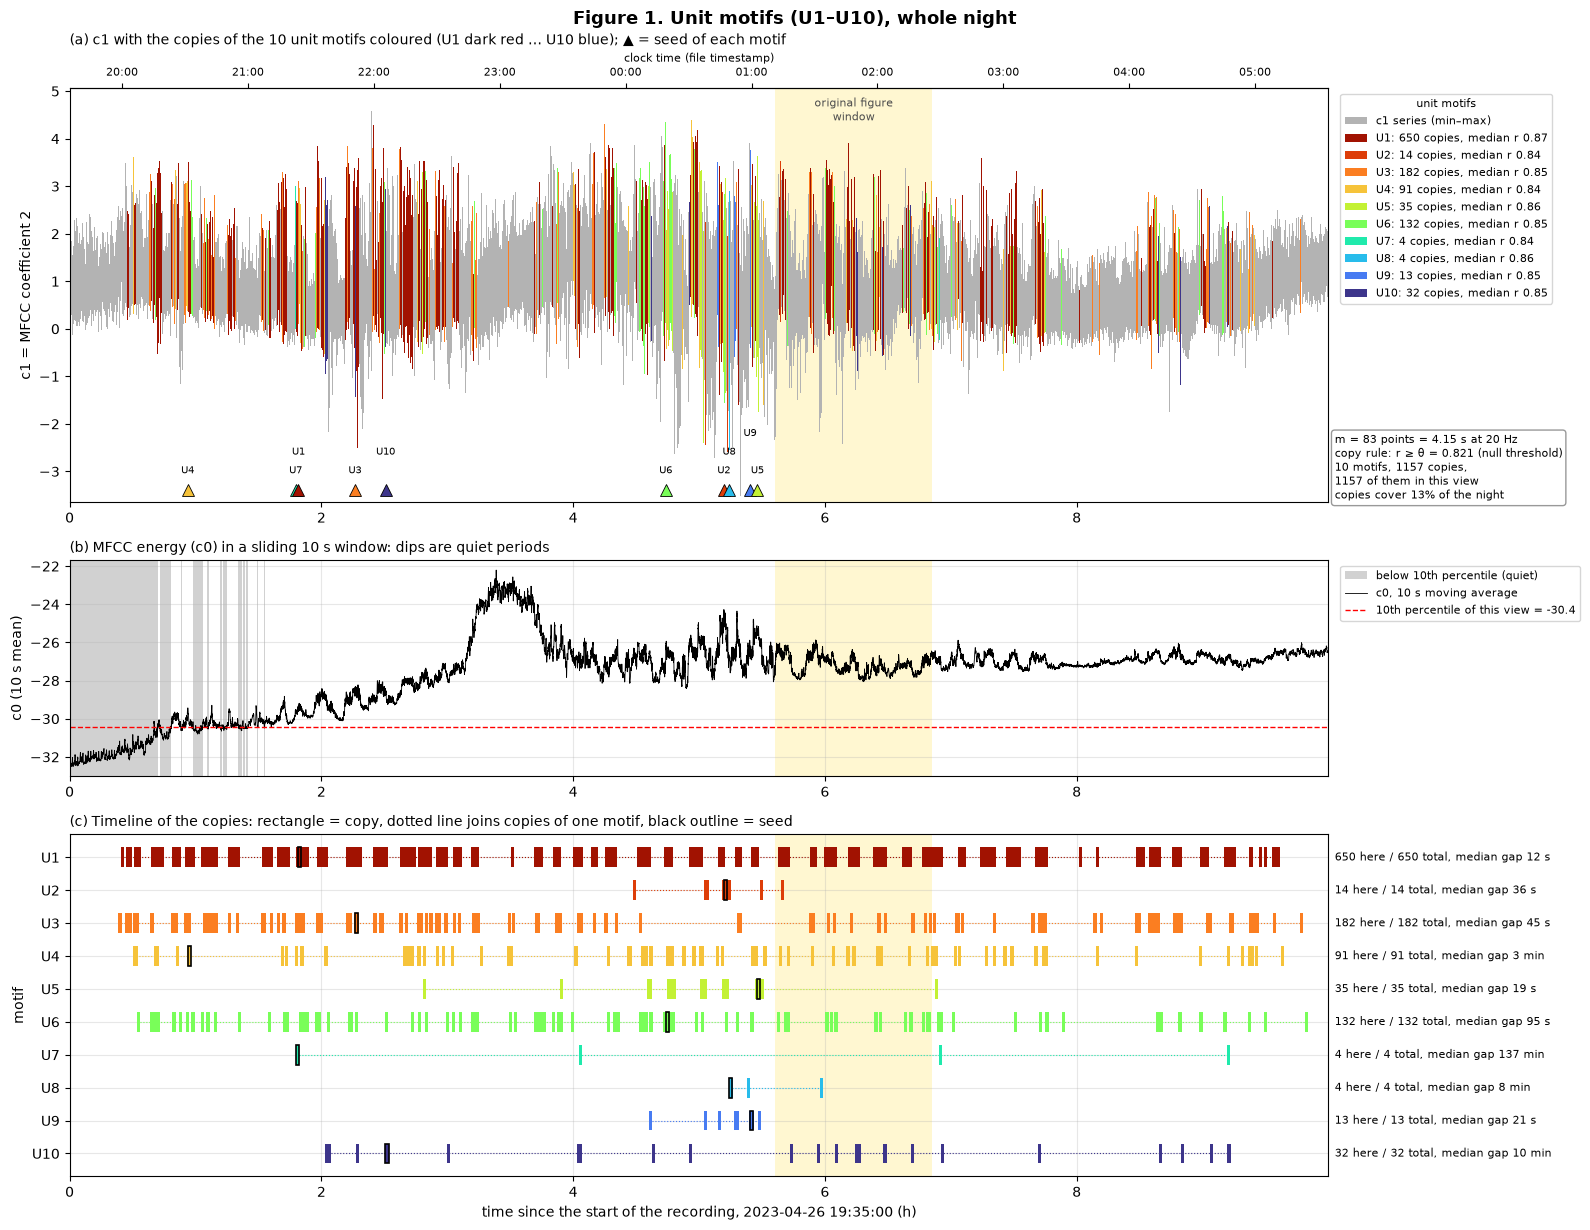

In [5]:
plot_level("unit", 0, DURATION, hours=True, title="Figure 1. Unit motifs (U1–U10), whole night", name="unit_night")

**Figure 1. Unit motifs over the whole night.** 1,157 copies of 10 unit motifs, each 4.15 s long. **U1** alone
has 650 copies spread from 0.41 h to 9.59 h with a median gap of about 12 s: it is the unit that repeats inside
almost every phrase (see Figure 18). U3 (182), U6 (132) and U4 (91) also last the whole night. **U2, U5 and U9**
are local: their copies sit only between ~2.8 and ~6.9 h (U2 4.48–5.65 h, U9 4.60–5.47 h), so these units belong to
a part of the song that is sung only in that stretch of the night. Panel (b) shows the c0 energy rising through
the night; the quiet periods (grey) are mostly in the first hour and a half, before singing becomes continuous,
and there are no unit copies in the first 0.38 h.

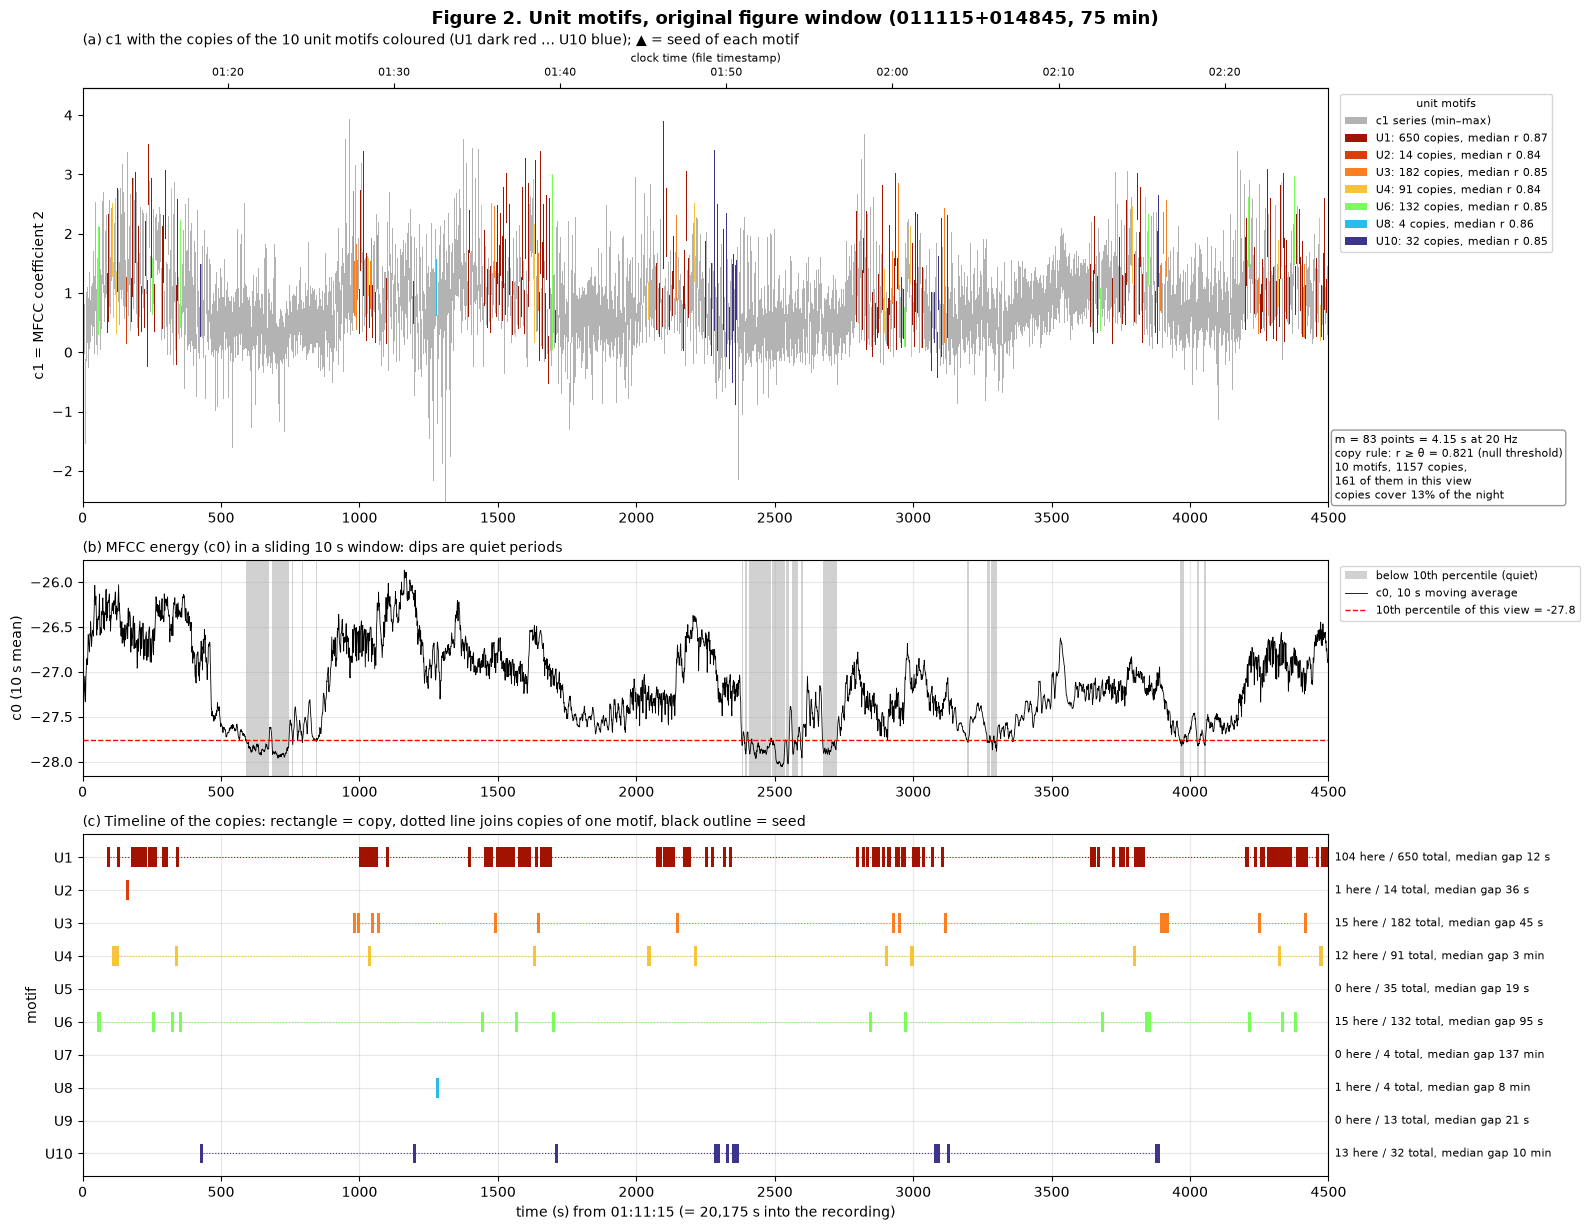

In [6]:
plot_level("unit", *IMAGE_WINDOW, title="Figure 2. Unit motifs, original figure window (011115+014845, 75 min)", name="unit_window")

**Figure 2. Unit motifs in the original figure's 75 minutes** (01:11:15–02:26:15; x axis in seconds from its
start, as in the original). 161 unit copies fall in these 75 minutes: 104 of U1, and 12–15 each of U3, U4, U6
and U10. The U1 copies come in **clusters** (around 150–350 s, 1,000–1,100 s, 1,450–1,700 s, 2,100–2,350 s,
2,800–3,050 s, 3,650–3,800 s and 4,200–4,500 s) separated by several minutes with few U1 copies: U1 belongs to
particular phrases (P1–P4, Figure 18) and is absent while the whale sings other themes. The grey shading in (b) is
computed with this window's own 10th percentile, so it marks the relative pauses within the song (e.g. 600–750 s
and 2,400–2,700 s), and U1 clusters stop during them.

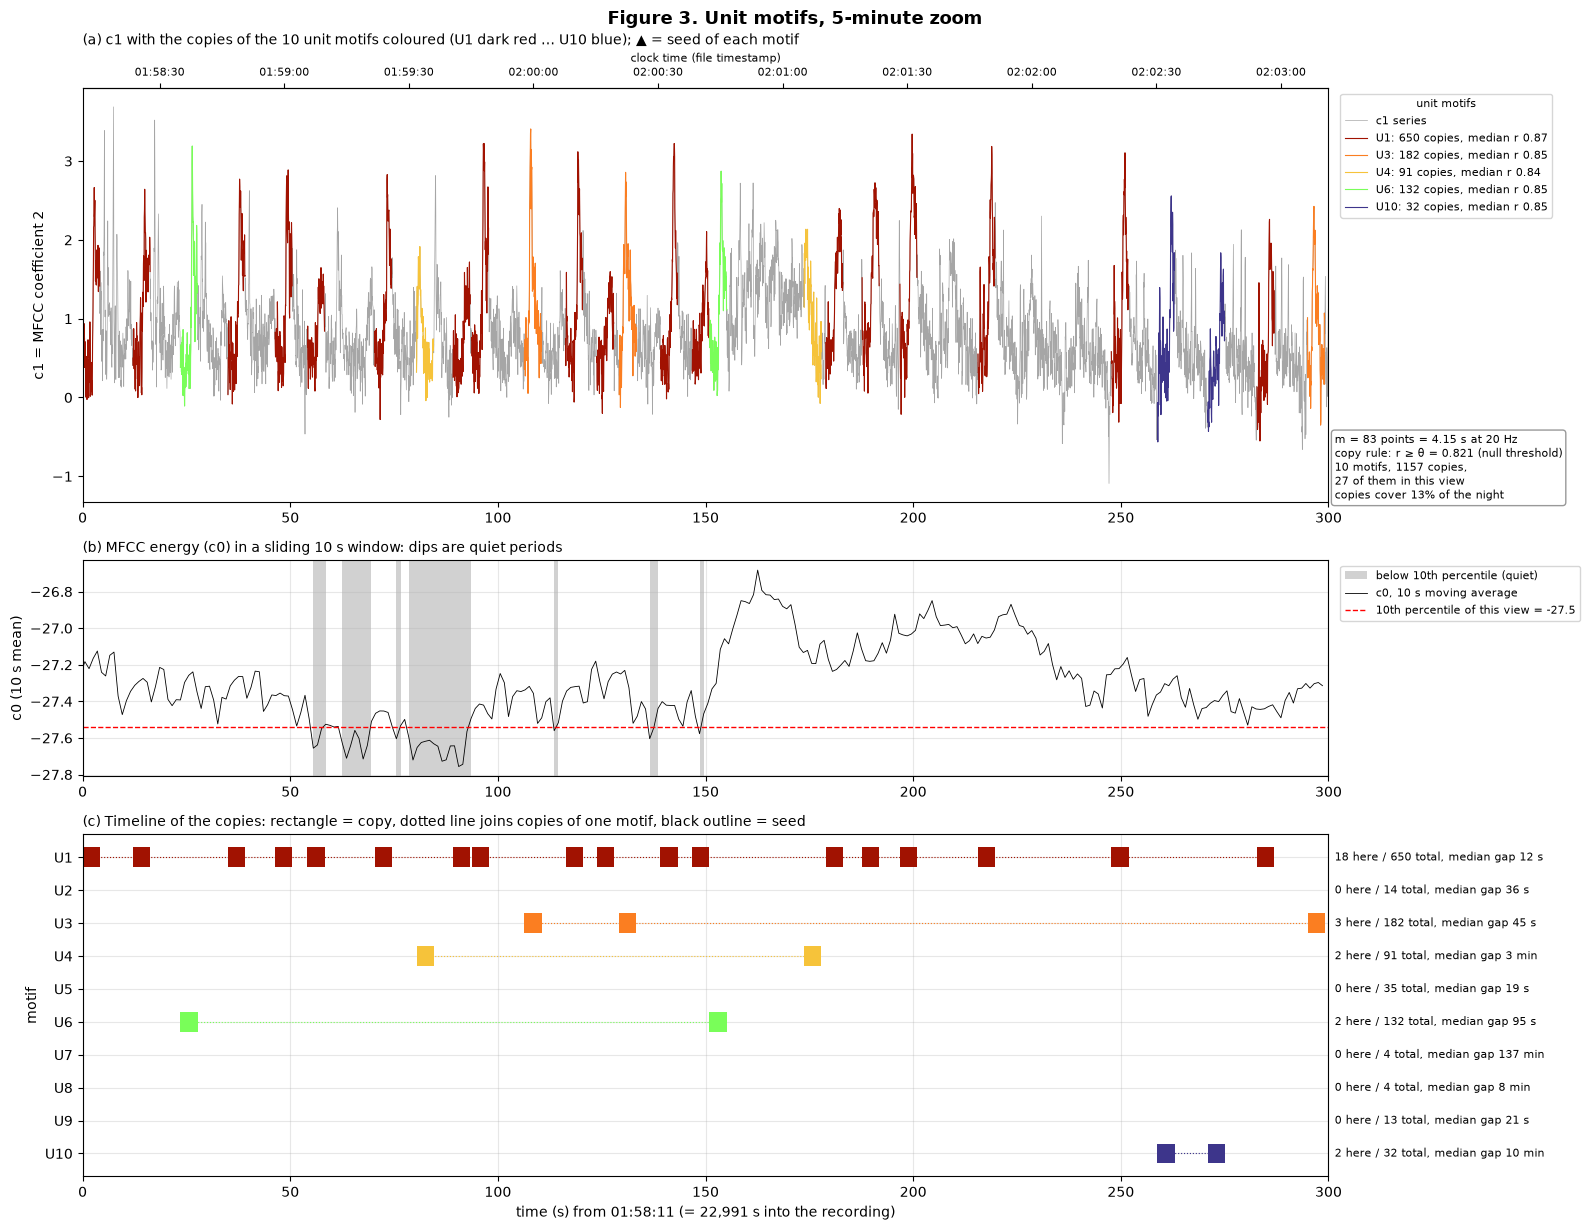

In [7]:
plot_level("unit", *busiest_window('unit', 300, *IMAGE_WINDOW), title="Figure 3. Unit motifs, 5-minute zoom", name="unit_zoom")

**Figure 3. Five minutes with the most unit copies (01:58:11–02:03:11).** At this scale each 4.15 s copy is visible
as a coloured stretch of c1, and the repeated shape (a sharp c1 peak followed by a decay) can be compared copy by
copy. U1 recurs every ~10–20 s (18 copies in 5 minutes), with U3, U4, U6 and U10 in some of the gaps between U1
copies. During the quiet stretch at 55–95 s (grey in b) the U1 copies keep coming but other units are absent.
This regular repetition of a short unit is the pattern that "a phrase contains units" predicts.

### Phrases (33 s)

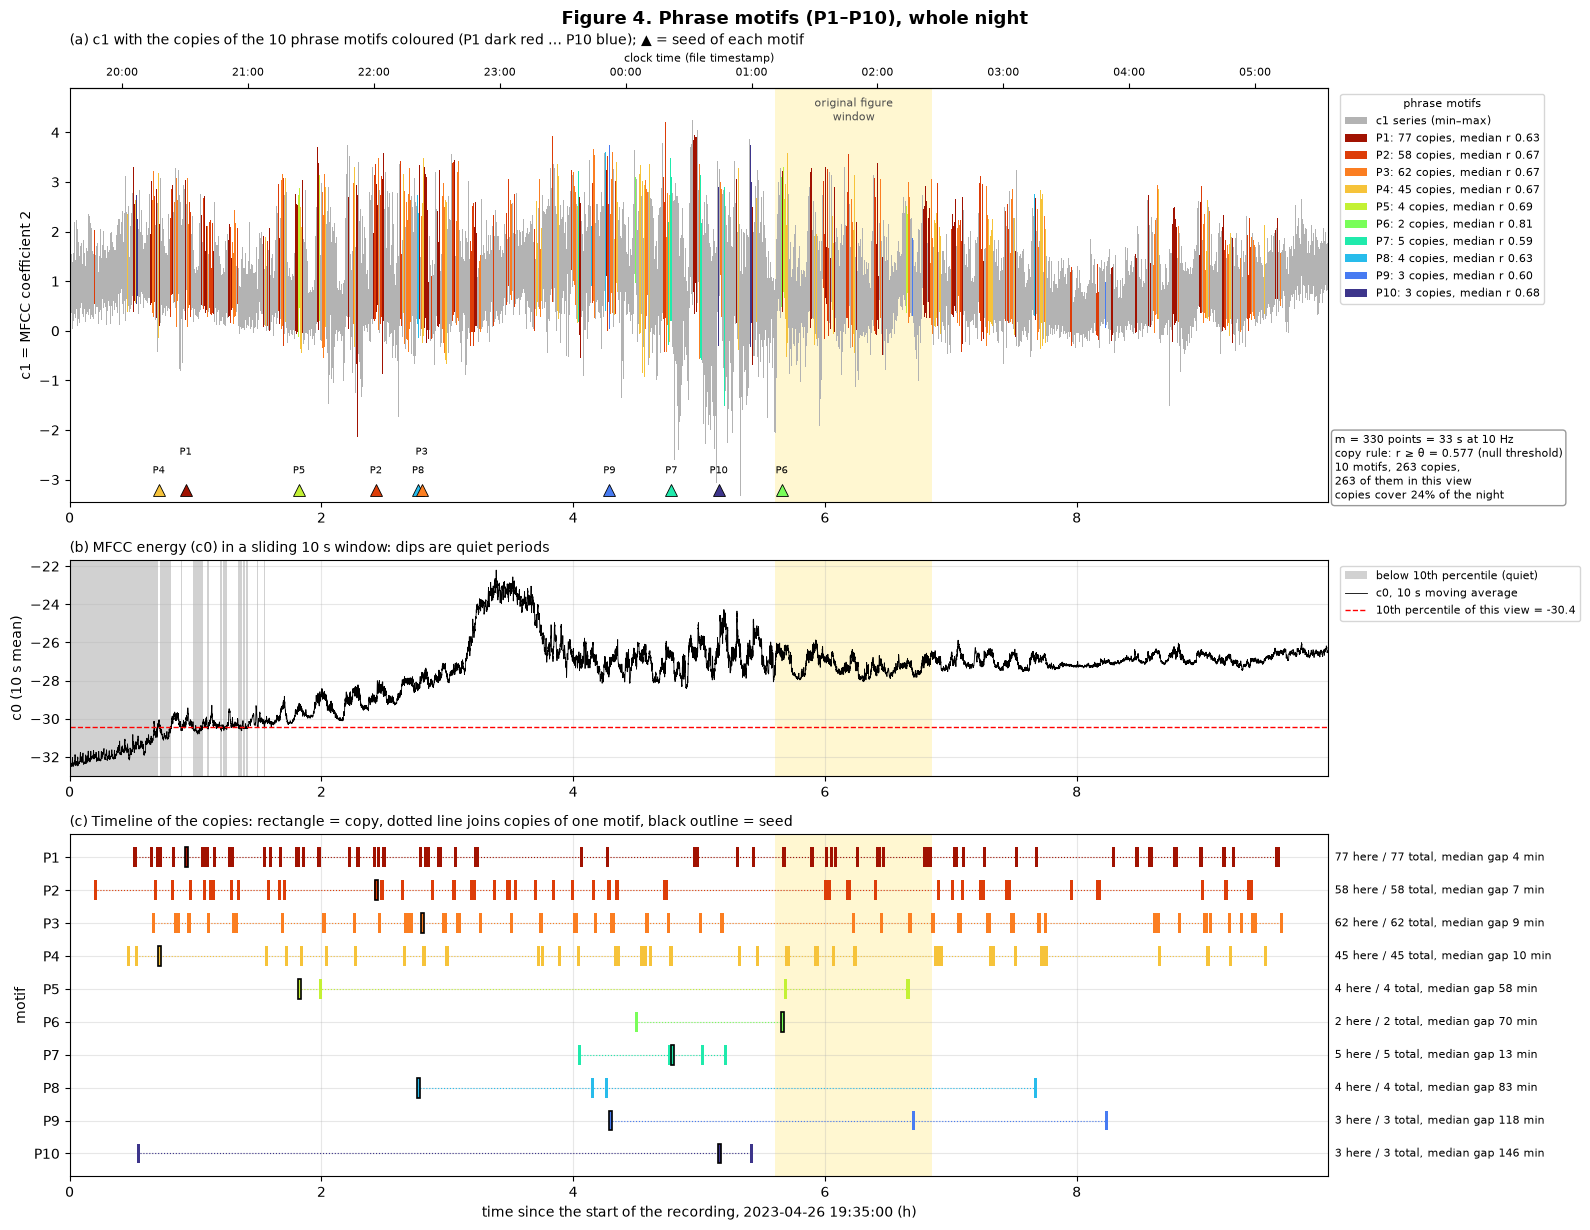

In [8]:
plot_level("phrase", 0, DURATION, hours=True, title="Figure 4. Phrase motifs (P1–P10), whole night", name="phrase_night")

**Figure 4. Phrase motifs over the whole night.** 263 copies of 10 phrase motifs, each 33 s long. Four phrases
dominate: **P1** (77 copies, median gap ~4 min), **P2** (58), **P3** (62) and **P4** (45), all present from the
first hour to the last. P5–P10 have 2–5 copies each and are mostly confined to the middle of the night
(P6 4.49–5.65 h, P7 4.04–5.20 h): rare variants or transitions.

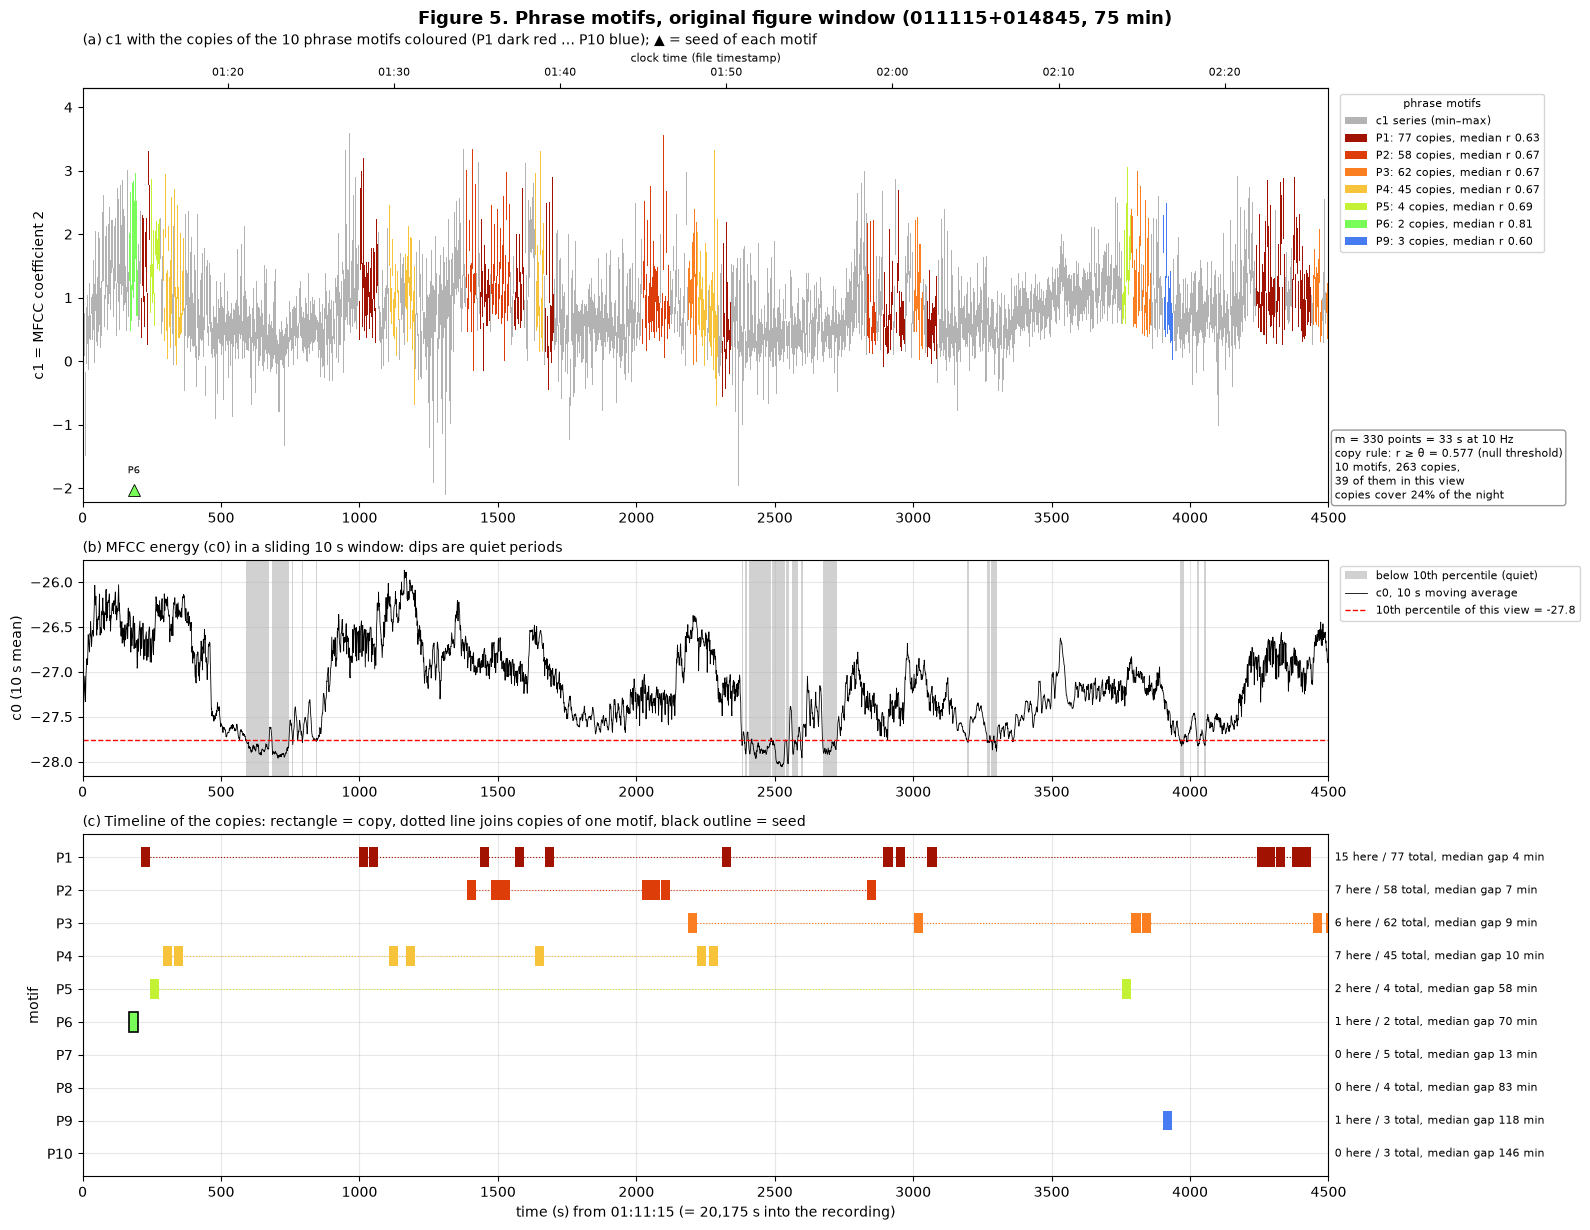

In [9]:
plot_level("phrase", *IMAGE_WINDOW, title="Figure 5. Phrase motifs, original figure window (011115+014845, 75 min)", name="phrase_window")

**Figure 5. Phrase motifs in the original figure's window.** 39 phrase copies: P1 (15), P2 (7), P3 (6) and P4
(7) alternate across the 75 minutes, with single copies of P5, P6 (its seed, at ~180 s) and P9. Copies of the same
phrase often come in pairs or runs (P1 at ~1,000–1,060 s and ~4,250–4,400 s, P2 at ~1,500 s and ~2,050 s, P4 at
~300 s and ~1,150 s): a phrase is repeated before the song moves on, the defining property of a theme. The phrase
copies coincide with the U1 clusters of Figure 2.

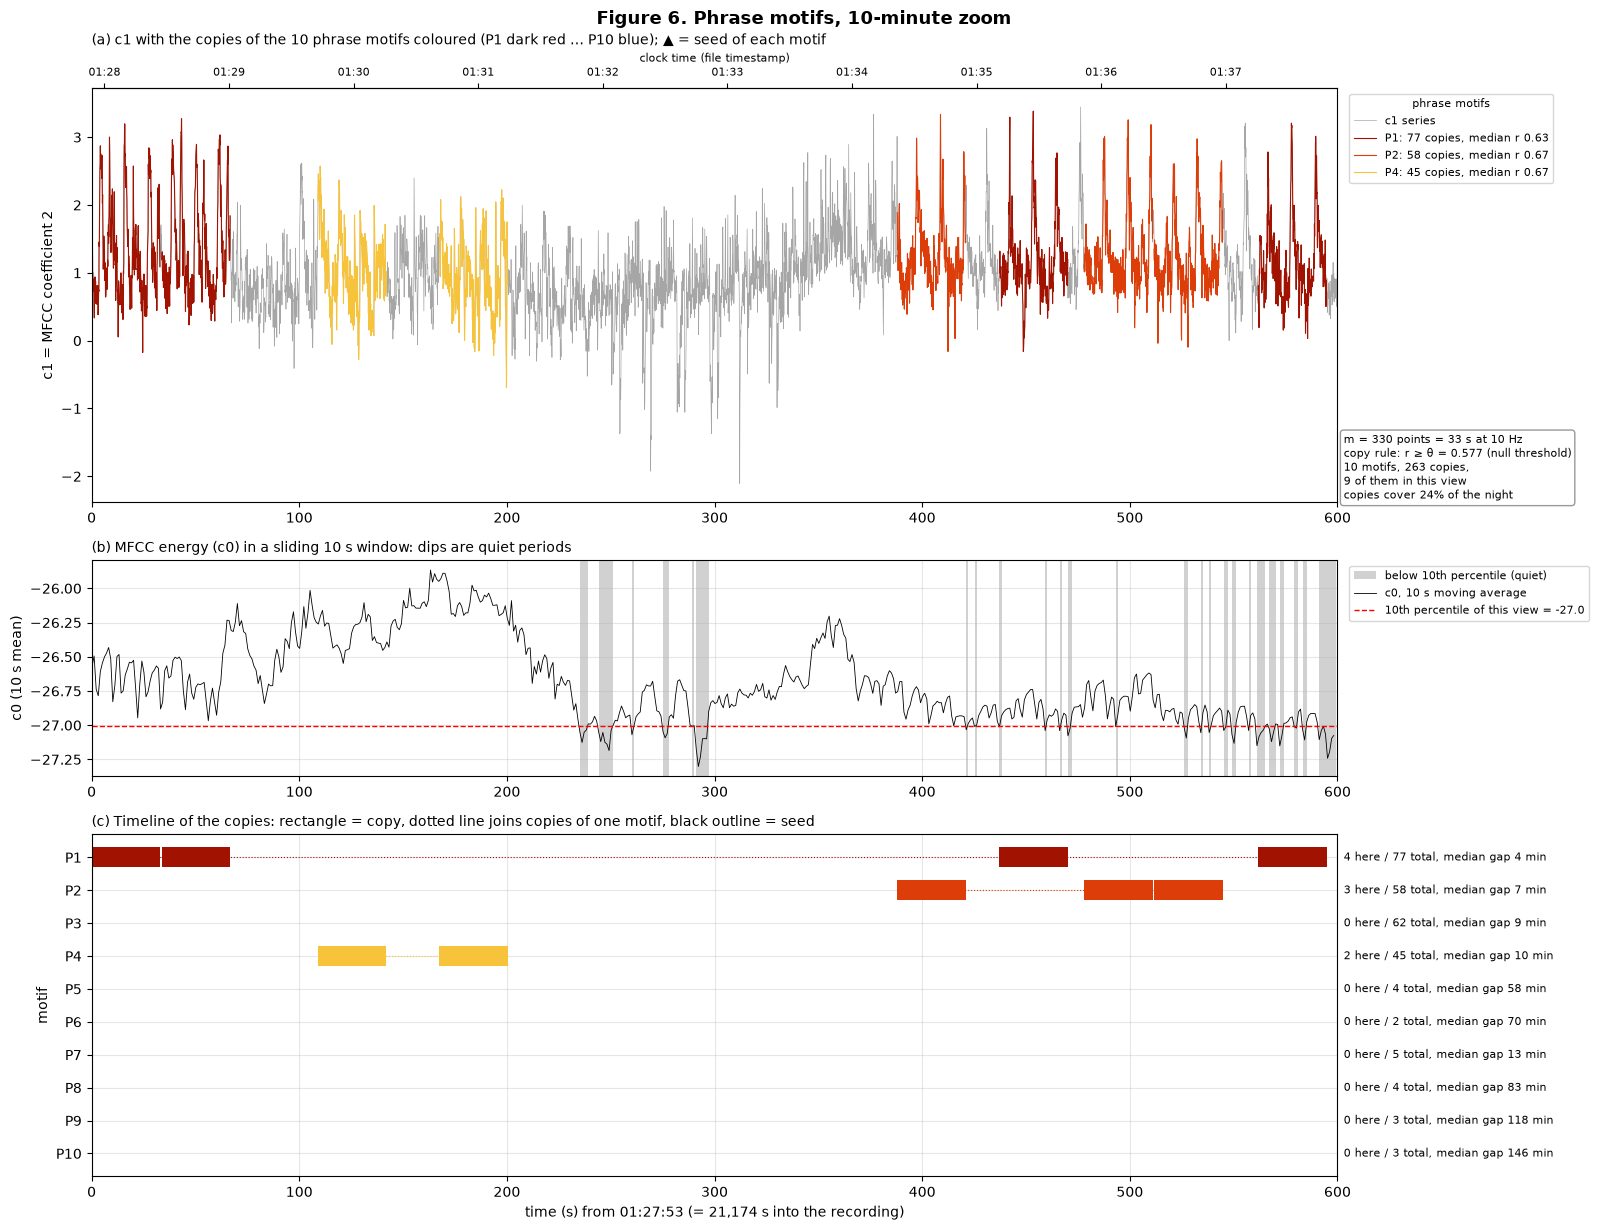

In [10]:
plot_level("phrase", *busiest_window('phrase', 600, *IMAGE_WINDOW), title="Figure 6. Phrase motifs, 10-minute zoom", name="phrase_zoom")

**Figure 6. Ten minutes with the most phrase copies (01:27:53–01:37:53).** Each 33 s copy is now a full coloured
stretch of c1, and the repeated shape (a train of 4–6 sharp c1 peaks, i.e. units) is visible inside every copy. The
sequence is P1 P1 (back to back), P4 P4, a stretch without phrase copies (200–390 s), then P2 P1 P2 P2 P1: each
phrase is sung two or more times in a row, then the song switches. The median gap of the main phrases over the
night (4–10 min) is longer than here because after a run of a phrase the song moves on to other themes.

### Themes (95 s)

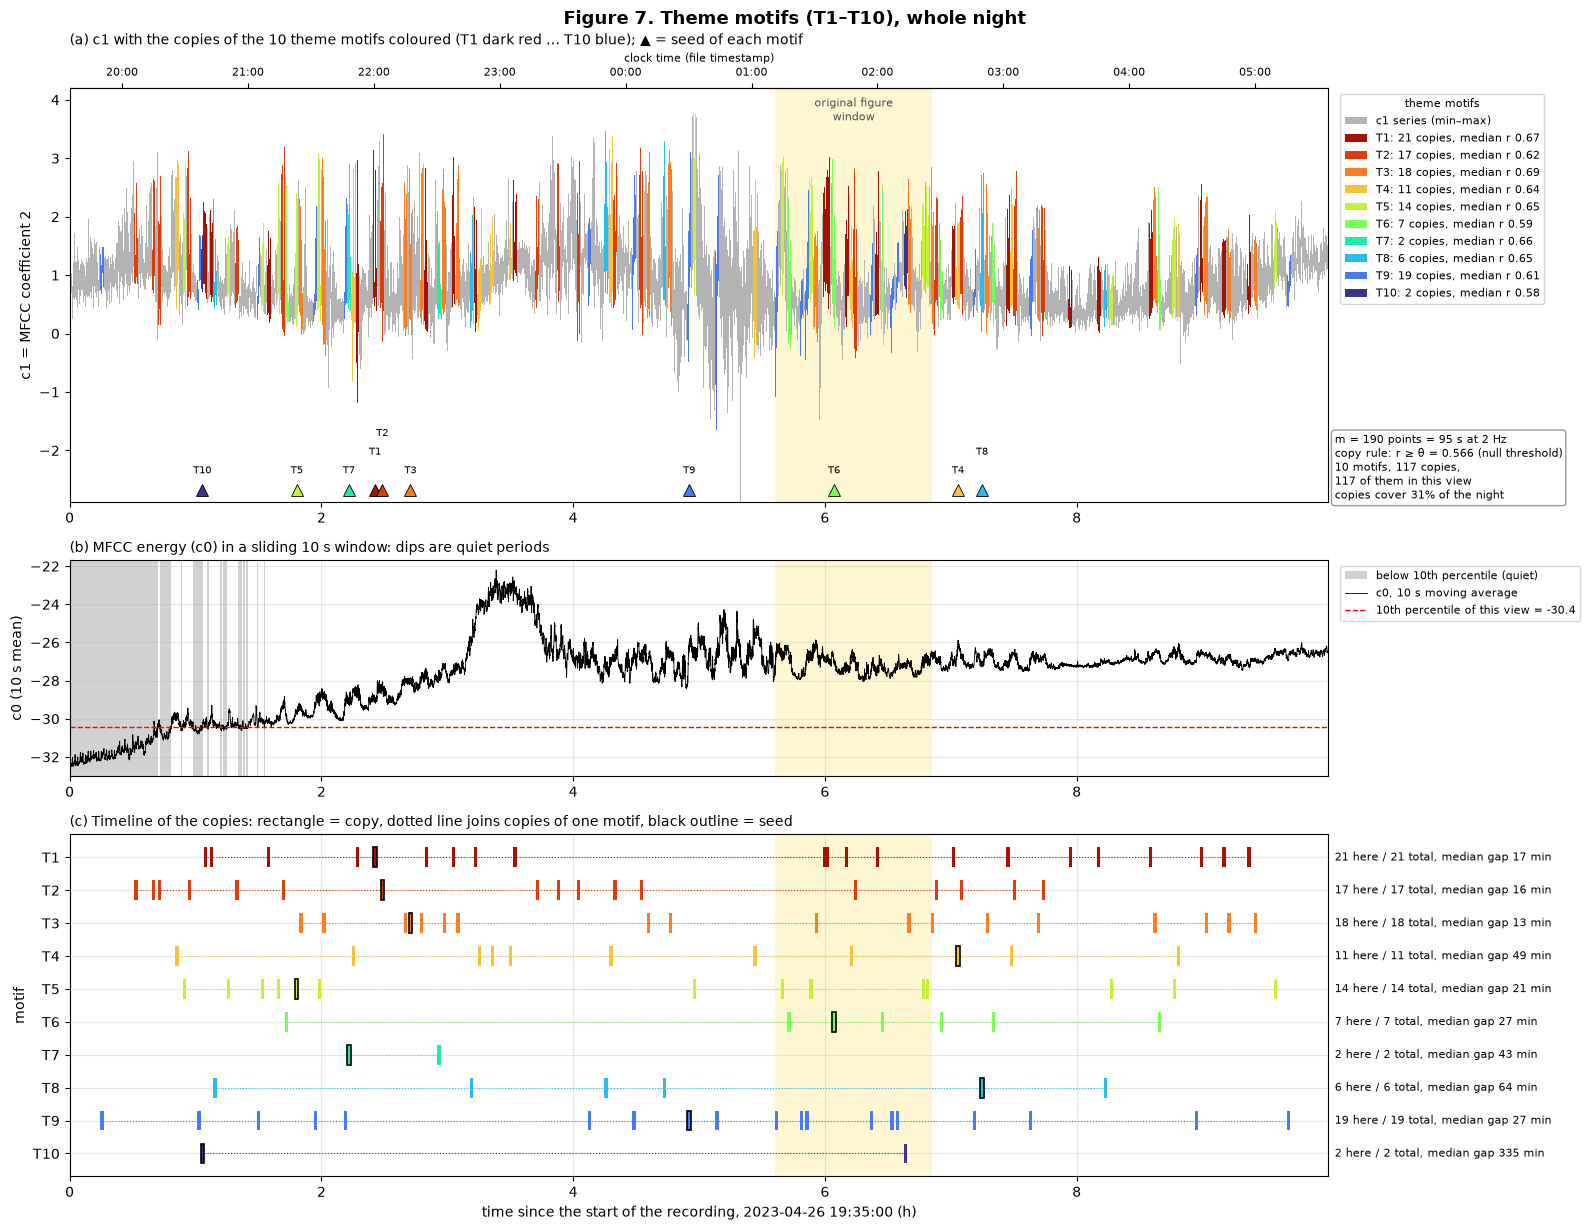

In [11]:
plot_level("theme", 0, DURATION, hours=True, title="Figure 7. Theme motifs (T1–T10), whole night", name="theme_night")

**Figure 7. Theme motifs over the whole night.** 117 copies of 10 theme motifs, each 95 s long, covering 31% of the
night. T1 (21 copies), T9 (19), T3 (18), T2 (17) and T5 (14) recur from the first to the last hour, i.e. the same
themes are sung all night. The median gap of the main themes is 13–27 min, close to the length of one song cycle.
T7 and T10 have only 2 copies.

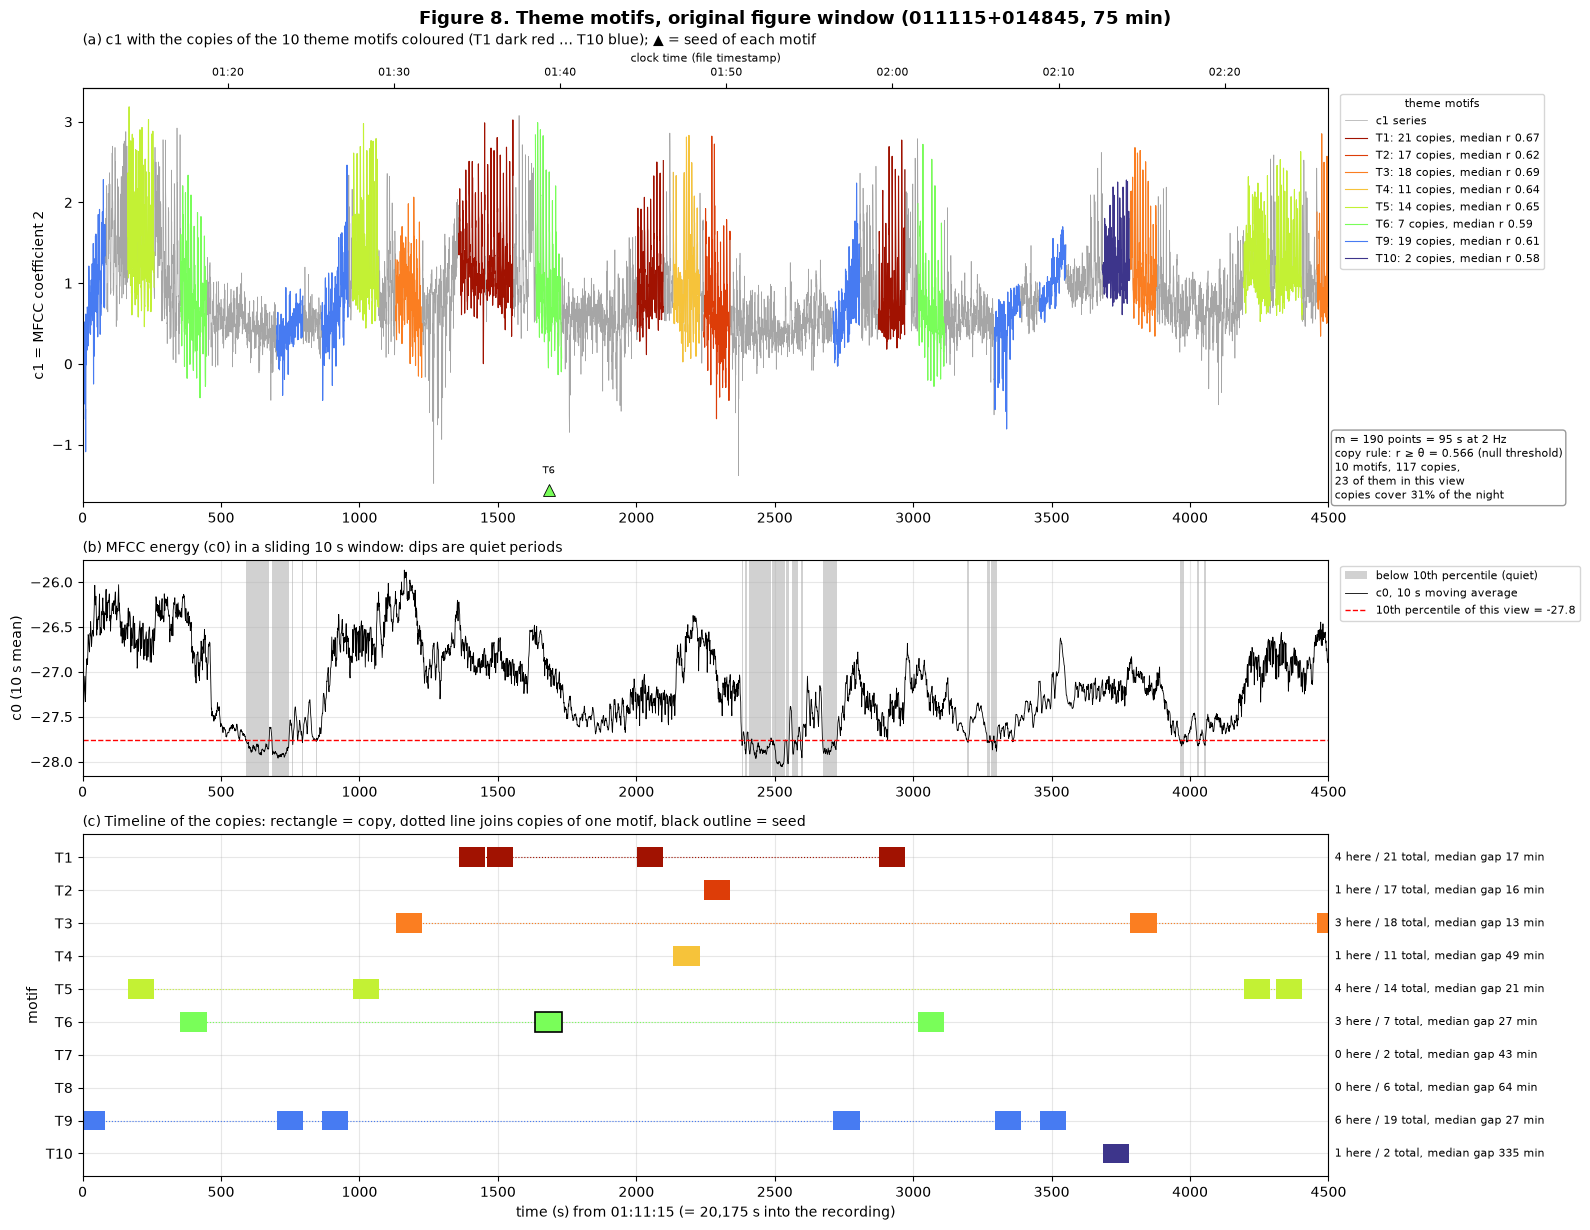

In [12]:
plot_level("theme", *IMAGE_WINDOW, title="Figure 8. Theme motifs, original figure window (011115+014845, 75 min)", name="theme_window")

**Figure 8. Theme motifs in the original figure's window.** 23 theme copies: T9 (6), T1 and T5 (4 each), T3 and
T6 (3 each), and single copies of T2, T4 and T10. Each theme returns every ~15–25 minutes (about once per song
cycle). Some local orderings recur: T9 comes in pairs (~730/900 s and ~3,300/3,480 s), each pair followed within a
few minutes by T5 or T10 and then T3; T1 is followed by T6 twice (~1,500 → 1,680 s and ~2,900 → 3,050 s). The T6
seed is at ~1,680 s (black outline). The 95 s theme copies have the same scale and rhythm of repetition as the
70 s motifs of the original figure.

### Songs (600 s)

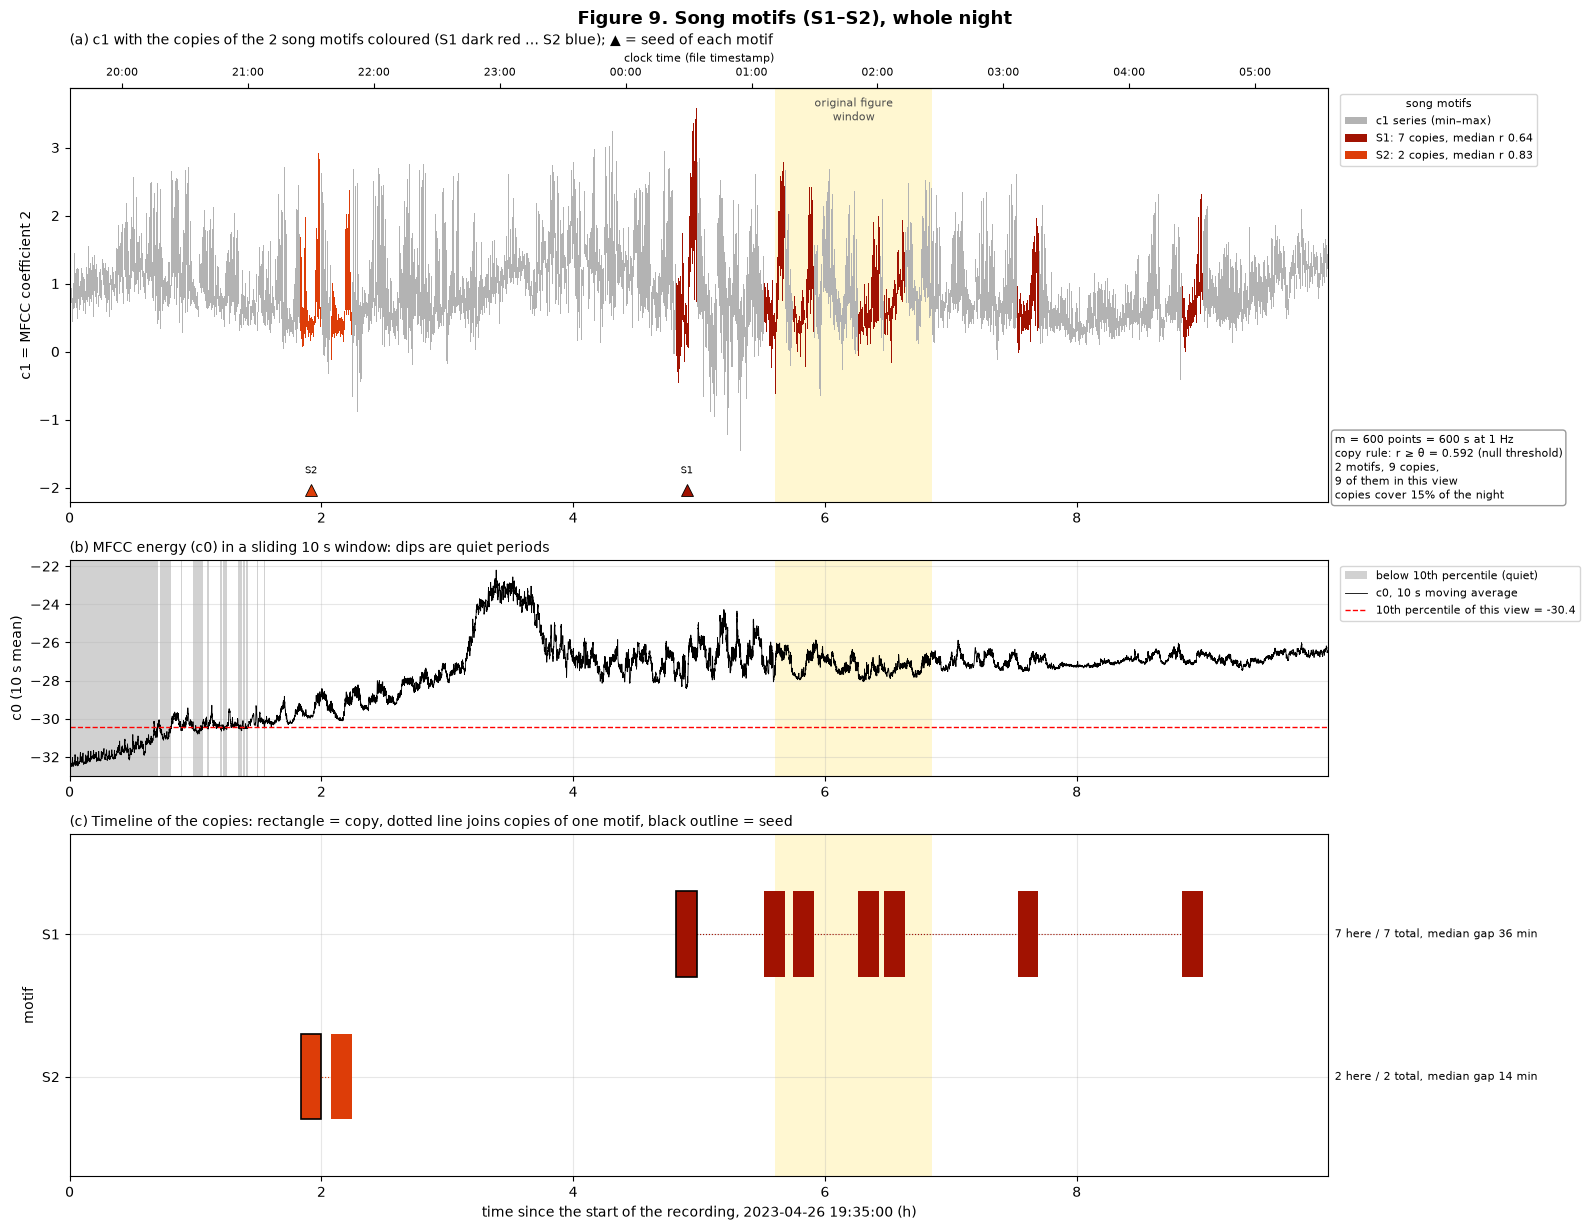

In [13]:
plot_level("song", 0, DURATION, hours=True, title="Figure 9. Song motifs (S1–S2), whole night", name="song_night")

**Figure 9. Song motifs over the whole night.** Only two 600 s motifs reach the threshold: **S1** has 7 copies
between 4.82 h and 8.84 h (median gap ~36 min; four of them in the original figure's window) and **S2** has 2
copies at 1.83 h and 2.07 h, 14 minutes apart (about one song cycle). Ten-minute windows rarely correlate above
the null level because slow loudness changes dominate c1 at this scale (note the energy rise to its maximum at
~3.5 h in panel b), so the song level is the weakest part of the analysis.

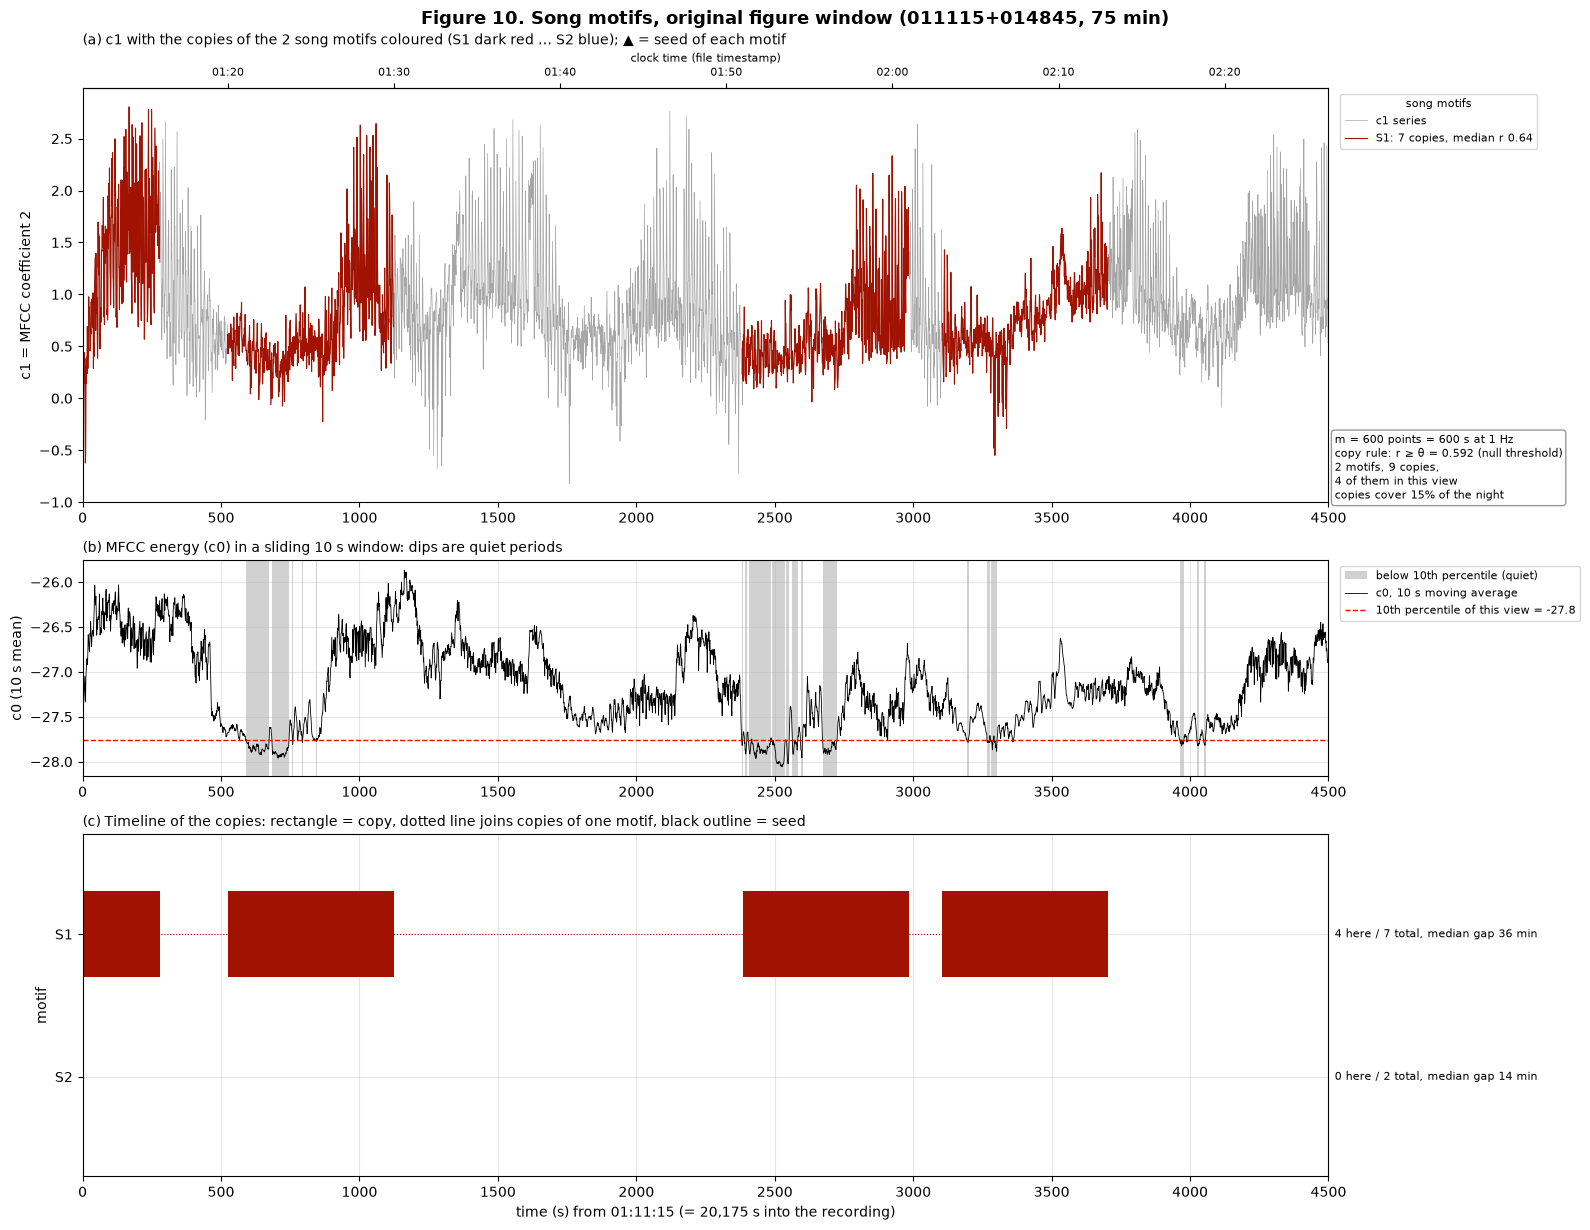

In [14]:
plot_level("song", *IMAGE_WINDOW, title="Figure 10. Song motifs, original figure window (011115+014845, 75 min)", name="song_window")

**Figure 10. Song motifs in the original figure's window.** Four S1 copies overlap the 75 minutes. Compare with
the original figure, whose 70 s motifs repeat at the same rhythm: the 600 s S1 copies span several of those
shorter motifs.

## Does a song contain themes, a theme phrases, a phrase units?

### All levels on one time axis

One row per level (song at the top, unit at the bottom), each copy coloured by its motif number with the same
colours as above; the label (e.g. **T3**) is written inside when there is room. Grey background = quiet periods (c0
10 s mean below its 10th percentile over the **whole night**). If the hierarchy holds, the copies of a song motif
should sit on top of the same theme motifs, and so on down to units. In the zoomed views, thin dotted lines extend
the start and end of every higher-level copy down through the lower rows, so nesting can be read directly: a
lower copy between the two lines of a higher copy is inside it.

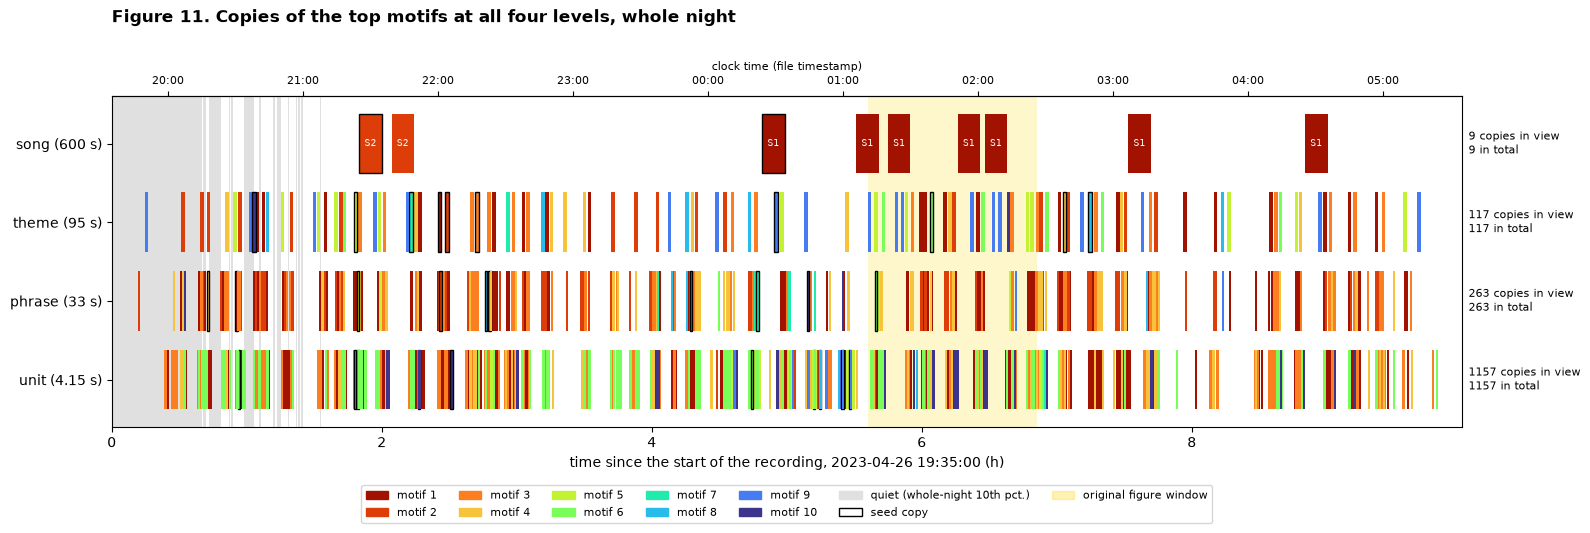

In [15]:
def plot_all_levels(t0, t1, hours=False, title="", name=None, guides=False):
    scale, origin = (3600.0, 0.0) if hours else (1.0, t0)
    X = lambda s: (np.asarray(s, dtype=float) - origin) / scale
    fig, ax = plt.subplots(figsize=(16, 5.6))
    for a, b in quiet_runs(t0, t1):
        ax.axvspan(X(a), X(b), color="0.88", lw=0, zorder=0)
    if hours and IMAGE_WINDOW[1] > t0 and IMAGE_WINDOW[0] < t1:
        ax.axvspan(X(IMAGE_WINDOW[0]), X(IMAGE_WINDOW[1]), color="gold", alpha=0.2, lw=0, zorder=0)
    min_w = (t1 - t0) / scale / 600
    for row, level in enumerate(ORDER):
        y = len(ORDER) - 1 - row
        tab, let = TOP[level], LETTER[level]
        inside = in_view(tab, t0, t1)
        for _, c in inside.iterrows():
            a, L, mi = c["start_s"], c["length_s"], int(c["motif"])
            wdt = max(L / scale, min_w)
            is_seed = a == SEEDS[level].loc[mi, "start_s"]
            ax.add_patch(Rectangle((X(a), y - 0.38), wdt, 0.76, fc=COLORS[mi - 1], ec="k" if is_seed else "none",
                                   lw=1 if is_seed else 0, zorder=2))
            if wdt > (t1 - t0) / scale / 60:
                ax.text(X(a) + wdt / 2, y, f"{let}{mi}", ha="center", va="center", fontsize=6.5,
                        color="w" if mi in (1, 2, 9, 10) else "k", zorder=3)
            if guides and level != "unit":
                for edge in (a, a + L):
                    ax.plot([X(edge)] * 2, [y - 0.38, -0.5], ls=":", lw=0.7, c=COLORS[mi - 1], zorder=1)
        ax.text(1.005, y, f"{len(inside)} {'copy' if len(inside) == 1 else 'copies'} in view\n{len(tab)} in total",
                transform=ax.get_yaxis_transform(), va="center", fontsize=8)
    ax.set_yticks(range(len(ORDER)))
    ax.set_yticklabels([f"{lvl} ({LEVELS[lvl]['length_s']:g} s)" for lvl in ORDER][::-1])
    ax.set_ylim(-0.6, len(ORDER) - 0.4)
    ax.set_xlim(X(t0), X(t1))
    ax.set_xlabel("time since the start of the recording, 2023-04-26 19:35:00 (h)" if hours else
                  f"time (s) from {clock(t0, '%H:%M:%S')} (= {t0:,.0f} s into the recording)")
    ax.set_title(title, loc="left", fontsize=12, fontweight="bold", pad=28)
    add_clock_axis(ax, t0, t1, X)
    handles = [Patch(color=COLORS[i], label=f"motif {i + 1}") for i in range(K)]
    handles += [Patch(color="0.88", label="quiet (whole-night 10th pct.)"),
                Patch(fc="w", ec="k", label="seed copy")]
    if hours:
        handles.append(Patch(color="gold", alpha=0.3, label="original figure window"))
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=7, fontsize=8)
    fig.tight_layout()
    show(fig, name)


plot_all_levels(0, DURATION, hours=True, title="Figure 11. Copies of the top motifs at all four levels, whole night",
                name="all_night")

**Figure 11. All four levels over the whole night.** At this scale the rows show *where* each level is active.
Units and phrases start after the first ~0.4 h, as soon as the energy rises out of the quiet first hour. Themes
cover 31% of the night and phrases 24%, so most phrase copies have a theme copy above them. The song row is sparse:
S2 twice near 2 h, S1 seven times between 4.8 h and 8.8 h. The page-by-page timeline at the end of the notebook
shows the same data at a scale where every copy can be read.

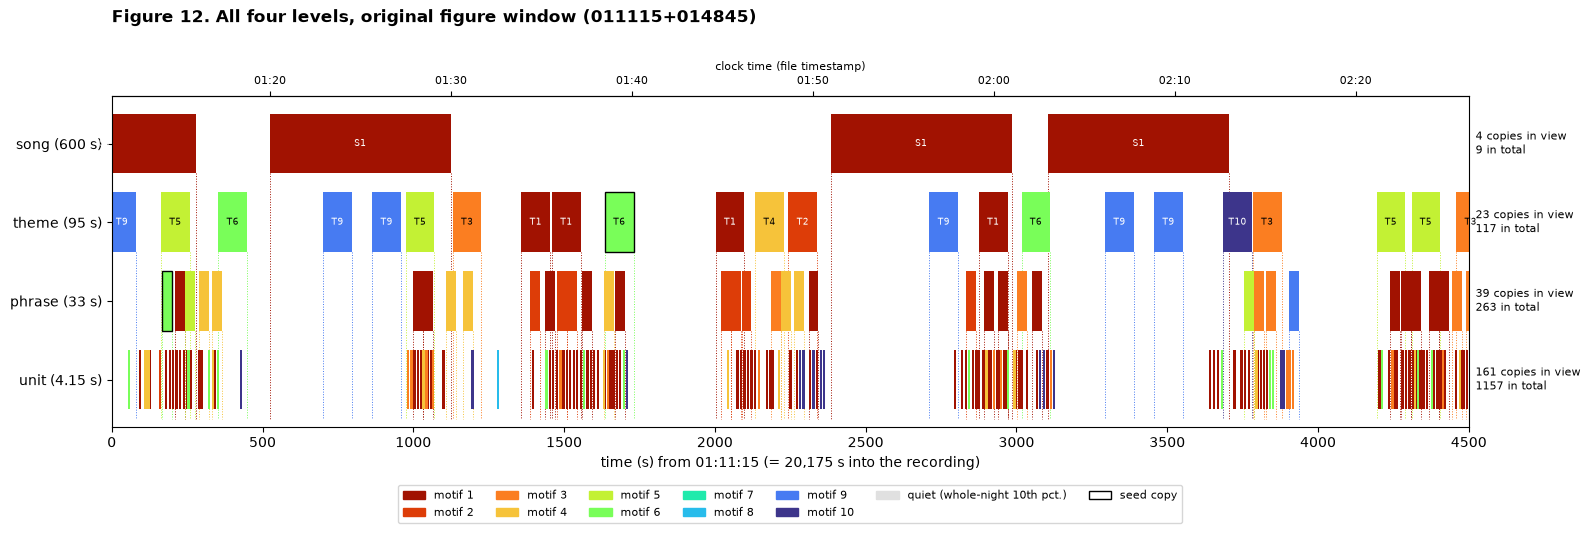

In [16]:
plot_all_levels(*IMAGE_WINDOW, title="Figure 12. All four levels, original figure window (011115+014845)",
                name="all_window", guides=True)

**Figure 12. All four levels in the original figure's 75 minutes.** The dotted guides from each song, theme and
phrase copy show nesting: most phrase copies fall between the guides of a theme copy, and the dense U1 clusters
sit between the guides of P1–P4 copies. Theme copies without phrase copies below them are mostly T9 (blue). Each
of the four S1 copies in view contains a T9 copy in its second half, which is what the consistency score in the
test below measures (Figure 16 shows all seven S1 copies aligned).

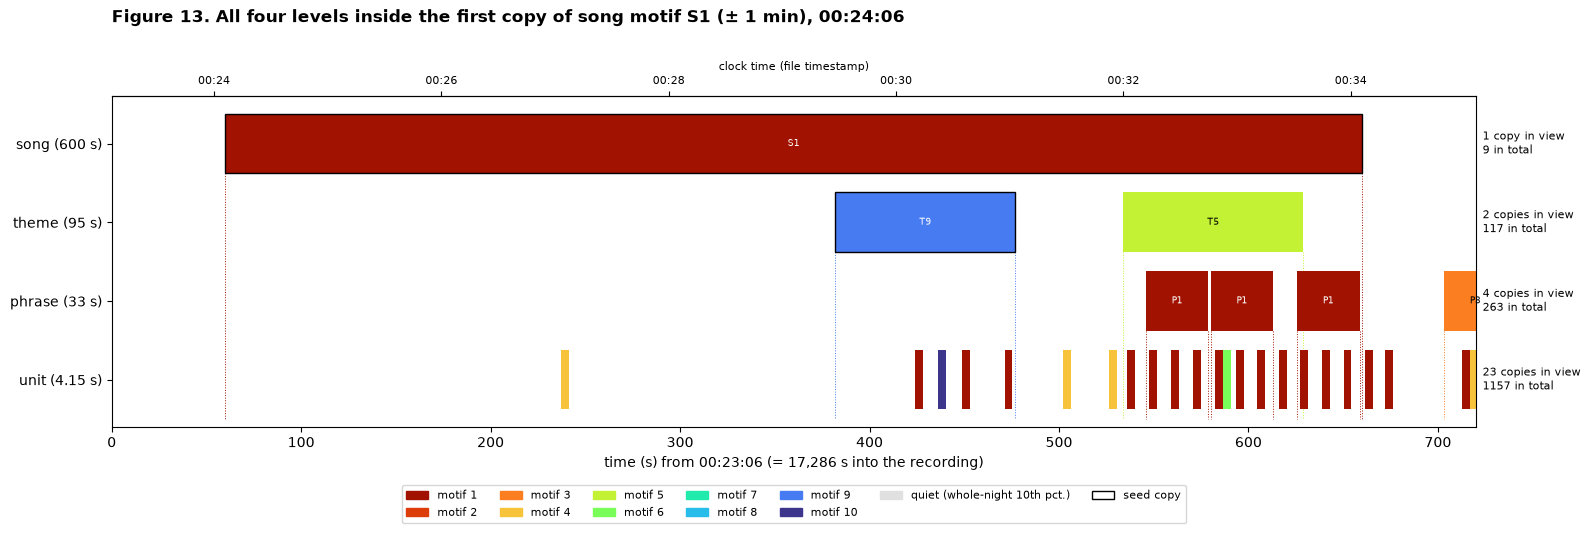

In [17]:
song1 = TOP["song"][TOP["song"]["motif"] == 1].sort_values("start_s").iloc[0]
plot_all_levels(song1["start_s"] - 60, song1["start_s"] + song1["length_s"] + 60, guides=True,
                title=f"Figure 13. All four levels inside the first copy of song motif S1 (± 1 min), "
                      f"{clock(song1['start_s'], '%H:%M:%S')}", name="all_song1")

**Figure 13. One song copy, zoomed (the S1 seed, 00:24:06–00:34:06, ± 1 minute).** The full 600 s copy is the top
row; the dotted lines mark its start and end and the start and end of every theme and phrase copy below it. The
nesting is visible in the second half: **T9** (~380–475 s) contains five U1 copies but no phrase copy, then **T5**
(~535–630 s) contains three back-to-back **P1** copies, each with three to four U1 copies inside. The first half of
the song (60–380 s) holds almost no motif copies at any level: that part of the song is not captured by the top-10
motifs of any level.

### Nesting test

A lower-level copy is **inside** a higher-level copy if at least 90% of it overlaps. For each pair of levels:

- **contain rate:** the fraction of higher-level copies that contain at least one lower-level copy;
- **inside rate:** the fraction of lower-level copies that lie inside some higher-level copy;
- **consistency:** for each higher-level motif, the mean pairwise Jaccard similarity of the *sets of lower-level
  motifs* inside its copies (1 = every copy contains exactly the same lower motifs), averaged over all pairs of
  copies. This is the key test: if a song is made of particular themes, two copies of the same song should contain
  the same themes.

**Null model.** All lower-level copies are shifted together by one random offset (wrapping around the night),
500 times. This keeps how many copies there are and how they are spaced, but breaks their alignment with the
higher level. The p-value is the fraction of shifts that score at least as high as the real data (smallest
possible value 1/501 ≈ 0.002).

In [18]:
PAIRS = [("song", "theme"), ("theme", "phrase"), ("phrase", "unit"), ("song", "phrase"), ("theme", "unit")]
HIER = {}
for up, lo in PAIRS:
    HIER[up, lo] = w.hierarchy_stats(TOP[up], TOP[lo], DURATION, n_null=500, seed=0)

rows = []
for (up, lo), h in HIER.items():
    row = {"pair": f"{up} ⊃ {lo}", "upper copies": len(TOP[up]), "lower copies": len(TOP[lo])}
    for key, name in (("contain_rate", "contain"), ("inside_rate", "inside"), ("consistency", "consistency")):
        row[f"{name}"] = round(h[key], 3)
        row[f"{name} null"] = round(float(np.nanmean(h["null"][key])), 3)
        row[f"{name} p"] = round(h["p"][key], 3)
    rows.append(row)
VERDICT = pd.DataFrame(rows).set_index("pair")
VERDICT

,upper copies,lower copies,contain,contain null,contain p,inside,inside null,inside p,consistency,consistency null,consistency p
pair,,,,,,,,,,,
song ⊃ theme,9,117,1.000,0.877,0.269,0.154,0.131,0.206,0.561,0.125,0.006
theme ⊃ phrase,117,263,0.761,0.389,0.004,0.529,0.224,0.002,0.388,0.035,0.004
phrase ⊃ unit,263,1157,0.939,0.425,0.002,0.597,0.218,0.002,0.425,0.064,0.002
song ⊃ phrase,9,263,0.889,0.917,0.832,0.080,0.142,0.990,0.320,0.331,0.557
theme ⊃ unit,117,1157,0.872,0.568,0.002,0.583,0.299,0.002,0.353,0.111,0.004


**Table 3. Hierarchy test.** For each pair (higher ⊃ lower): the observed contain rate, inside rate and consistency,
the mean of the same score over 500 shifted nulls, and the one-sided p-value. Small p = the real data nest better
than chance.

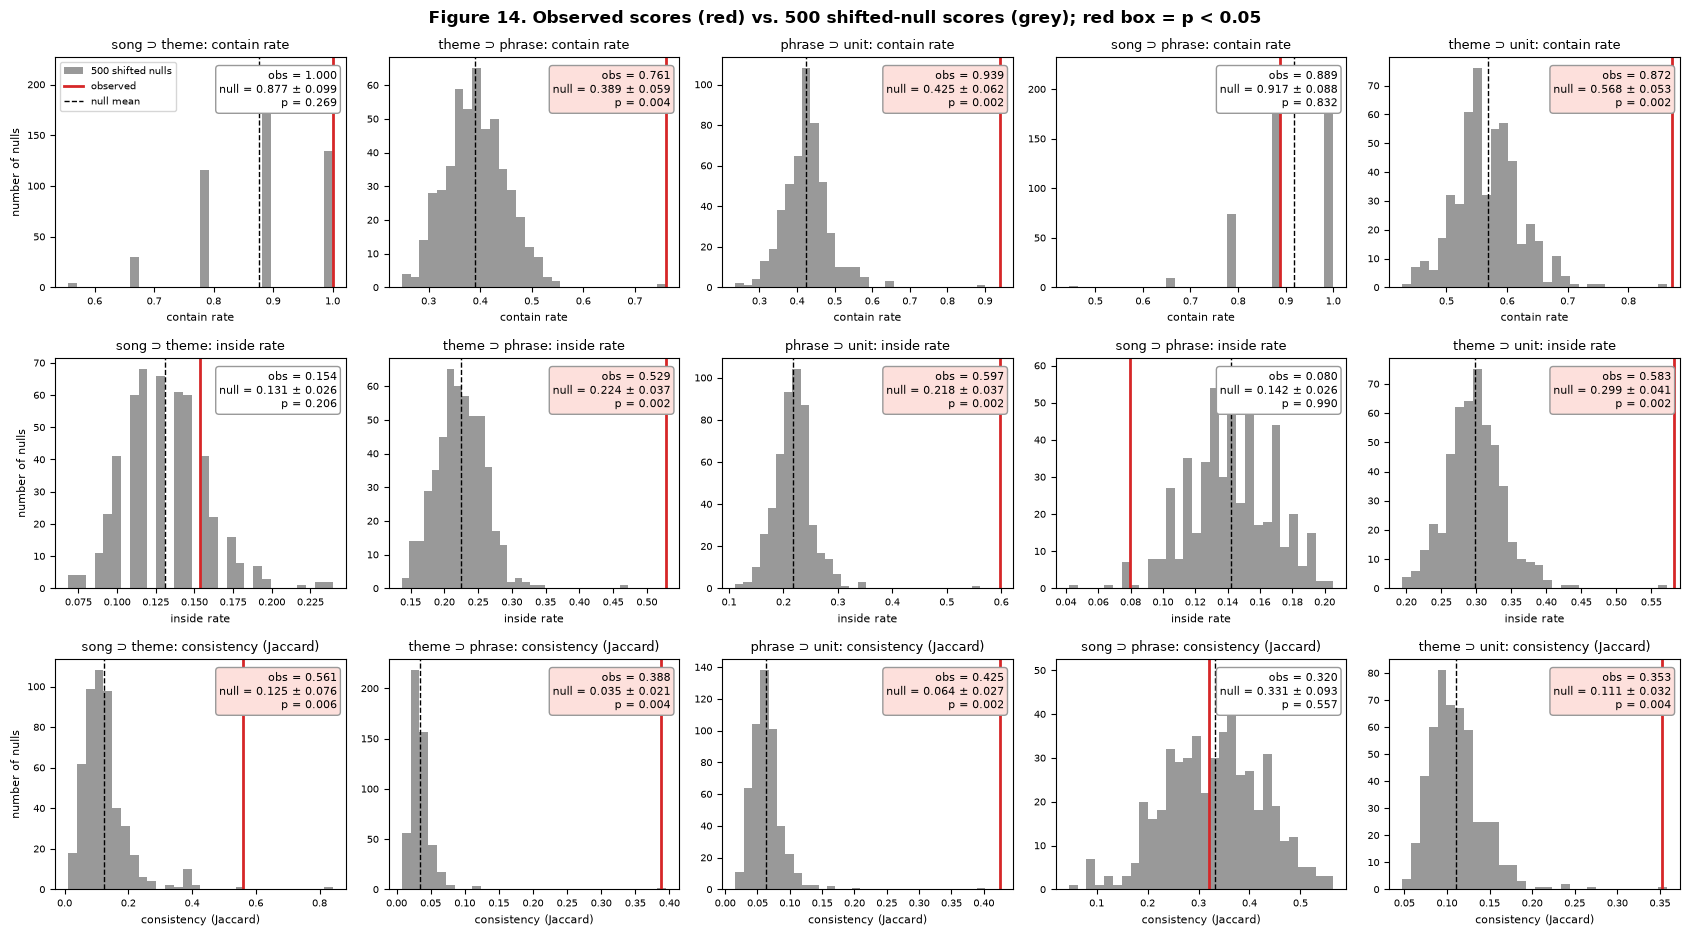

In [19]:
fig, axes = plt.subplots(3, len(PAIRS), figsize=(17, 9.5))
for j, ((up, lo), h) in enumerate(HIER.items()):
    for i, (key, name) in enumerate((("contain_rate", "contain rate"), ("inside_rate", "inside rate"),
                                     ("consistency", "consistency (Jaccard)"))):
        ax = axes[i, j]
        null = h["null"][key][np.isfinite(h["null"][key])]
        ax.hist(null, bins=30, color="0.6", label="500 shifted nulls")
        ax.axvline(h[key], c="C3", lw=2, label="observed")
        ax.axvline(null.mean(), c="k", ls="--", lw=1, label="null mean")
        p = h["p"][key]
        ax.text(0.97, 0.95, f"obs = {h[key]:.3f}\nnull = {null.mean():.3f} ± {null.std():.3f}\np = {p:.3f}",
                transform=ax.transAxes, ha="right", va="top", fontsize=8,
                bbox=dict(boxstyle="round", fc="#fde0dc" if p < 0.05 else "w", ec="0.6"))
        ax.set_title(f"{up} ⊃ {lo}: {name}", fontsize=9)
        ax.set_xlabel(name, fontsize=8)
        if j == 0:
            ax.set_ylabel("number of nulls", fontsize=8)
        ax.tick_params(labelsize=7)
axes[0, 0].legend(fontsize=7, loc="upper left")
fig.suptitle("Figure 14. Observed scores (red) vs. 500 shifted-null scores (grey); red box = p < 0.05",
             fontsize=12, fontweight="bold")
fig.tight_layout()
show(fig, "null_hist")

**Figure 14. Observed vs. null.** Each column is a pair of levels, each row a score. When the red line lies far to
the right of the grey histogram, the lower level nests inside the higher level more than chance allows. For
**phrase ⊃ unit**, **theme ⊃ phrase** and **theme ⊃ unit** all three scores are beyond every null (p ≤ 0.004). For
**song ⊃ theme** only the consistency is (p = 0.006): song copies contain the *same* themes, but containing *some*
theme is not unusual because themes cover a third of the night. **Song ⊃ phrase** is at or below the null on all
three scores.

### Which lower motifs are inside which higher motifs

Rows: higher-level motifs (with their number of copies); columns: lower-level motifs. Cell text: the percentage of
the higher motif's copies that contain at least one copy of the lower motif (blank = never). Colour: log2
enrichment over the shift null, log2((observed + 0.001) / (null + 0.001)); red = found inside that higher motif more
often than chance, blue = less often.

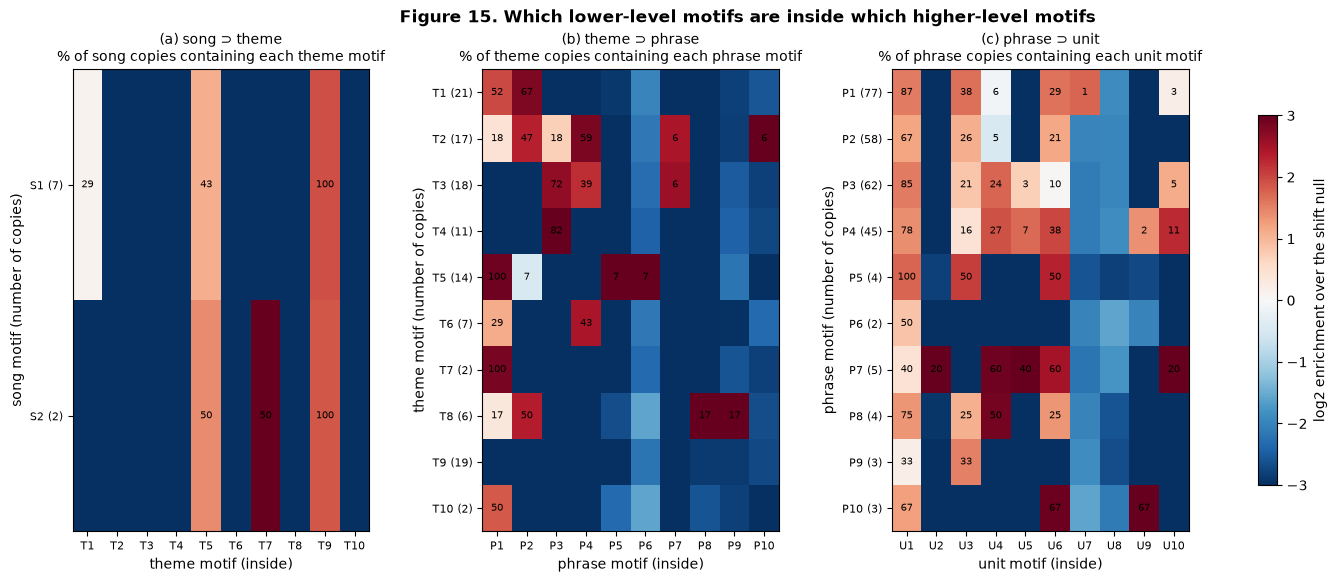

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, (up, lo), tag in zip(axes, PAIRS[:3], "abc"):
    h = HIER[up, lo]
    lu, ll = LETTER[up], LETTER[lo]
    im = ax.imshow(np.log2(h["enrichment"]), cmap="RdBu_r", vmin=-3, vmax=3, aspect="auto")
    for a in range(h["frac"].shape[0]):
        for b in range(h["frac"].shape[1]):
            if h["frac"][a, b] > 0:
                ax.text(b, a, f"{100 * h['frac'][a, b]:.0f}", ha="center", va="center", fontsize=7)
    ax.set_xticks(range(len(h["lower_ids"])))
    ax.set_xticklabels([f"{ll}{i}" for i in h["lower_ids"]], fontsize=8)
    ax.set_yticks(range(len(h["upper_ids"])))
    ax.set_yticklabels([f"{lu}{i} ({(TOP[up]['motif'] == i).sum()})" for i in h["upper_ids"]], fontsize=8)
    ax.set_xlabel(f"{lo} motif (inside)")
    ax.set_ylabel(f"{up} motif (number of copies)")
    ax.set_title(f"({tag}) {up} ⊃ {lo}\n% of {up} copies containing each {lo} motif", fontsize=10)
fig.subplots_adjust(wspace=0.38)
fig.colorbar(im, ax=axes, shrink=0.8, label="log2 enrichment over the shift null")
fig.suptitle("Figure 15. Which lower-level motifs are inside which higher-level motifs", fontsize=12,
             fontweight="bold")
show(fig, "enrichment")

**Figure 15. Enrichment of lower motifs inside higher motifs.** (a) Song ⊃ theme: every copy of S1 and S2
contains T9 (100%); S1 copies also contain T5 (43%) or T1 (29%), S2 copies T5 or T7 (50% each). (b) Theme ⊃ phrase:
T1 contains P1 (52%) and P2 (67%); T3 and T4 contain P3 (72%, 82%) and P4; T5 contains P1 in every copy; T2 mixes
P2 and P4. Each theme thus has its *own* phrases, as a theme should. T9's row is empty: theme 9 contains none of the
top-10 phrases. (c) Phrase ⊃ unit: U1 is inside 67–87% of the copies of P1–P4, and each phrase adds its own
secondary units (P1: U3 38%, U6 29%; P3: U4 24%, U3 21%; P4: U6 38%, U4 27%).

### Barcodes: what is inside each copy

For each higher-level motif, one row per copy (labelled with its clock time, hours since 19:35 and its correlation
r with the seed; ★ = the seed). The bottom x axis is the relative position inside the copy (0 = start, 1 = end),
the top x axis the same position in seconds. The blocks are the lower-level copies inside it, coloured by lower
motif. **If the hierarchy holds, the blocks line up vertically**: every copy of a song contains the same themes in
the same places. At most 30 copies (the best-matching ones) are shown per motif, in time order.

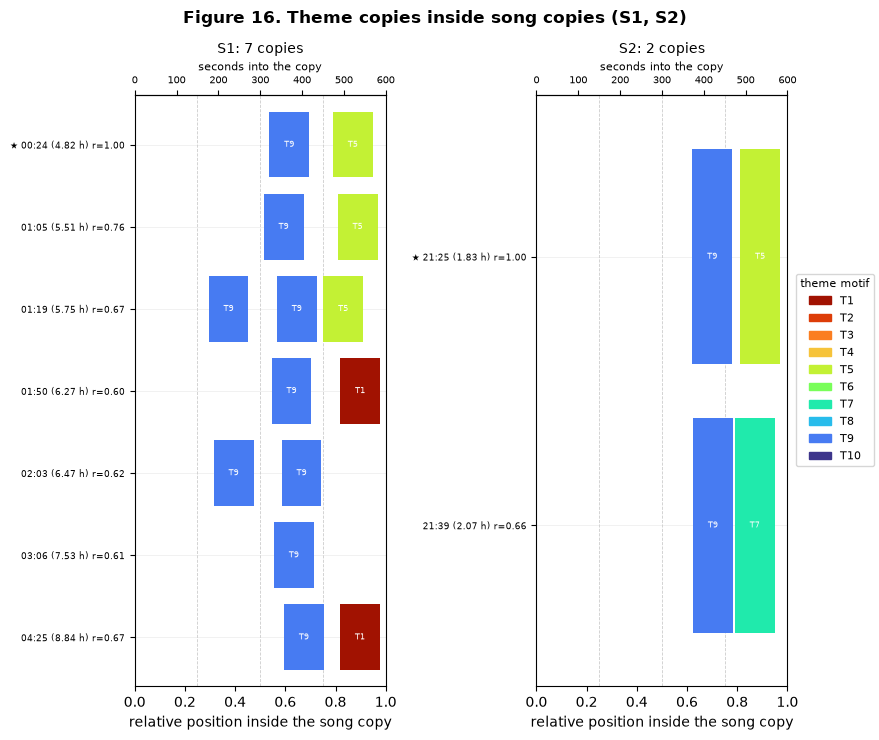

In [21]:
def barcode(up, lo, n_motifs=4, max_rows=30, title="", name=None):
    tab_u, tab_l, pairs = TOP[up], TOP[lo], HIER[up, lo]["pairs"]
    lu, ll, L = LETTER[up], LETTER[lo], LEVELS[up]["length_s"]
    motifs = tab_u["motif"].value_counts().index[:n_motifs].sort_values()
    fig, axes = plt.subplots(1, len(motifs), figsize=(4.4 * len(motifs), 7.5), squeeze=False)
    for ax, mi in zip(axes[0], motifs):
        rows = tab_u[tab_u["motif"] == mi].sort_values("r", ascending=False).head(max_rows).sort_values("start_s")
        for r, u in enumerate(rows.index):
            ax.axhline(r, c="0.92", lw=0.5, zorder=0)
            for _, p in pairs[pairs["upper"] == u].iterrows():
                lm = int(tab_l["motif"].iloc[int(p["lower"])])
                ax.add_patch(Rectangle((p["rel_start"], r - 0.4), p["rel_end"] - p["rel_start"], 0.8,
                                       color=COLORS[lm - 1], lw=0))
                if (p["rel_end"] - p["rel_start"]) > 0.12:
                    ax.text((p["rel_start"] + p["rel_end"]) / 2, r, f"{ll}{lm}", ha="center", va="center",
                            fontsize=6, color="w")
        for v in (0.25, 0.5, 0.75):
            ax.axvline(v, c="0.8", lw=0.6, ls="--", zorder=0)
        if not pairs["upper"].isin(rows.index).any():
            ax.text(0.5, 0.5, f"no {lo} copy inside\nany {lu}{mi} copy", transform=ax.transAxes, ha="center",
                    va="center", fontsize=10, color="0.4", bbox=dict(fc="w", ec="0.7"))
        labels = [f"{'★ ' if c['r'] >= 0.9999 else ''}{clock(c['start_s'])} ({c['start_s'] / 3600:.2f} h) "
                  f"r={c['r']:.2f}" for _, c in rows.iterrows()]
        ax.set_yticks(range(len(rows)))
        ax.set_yticklabels(labels, fontsize=6.5)
        ax.set_ylim(-0.6, len(rows) - 0.4)
        ax.invert_yaxis()
        ax.set_xlim(0, 1)
        ax.set_xlabel(f"relative position inside the {up} copy")
        top = ax.secondary_xaxis("top", functions=(lambda x, L=L: x * L, lambda s, L=L: s / L))
        top.set_xlabel("seconds into the copy", fontsize=8)
        top.tick_params(labelsize=7)
        n_tot = (tab_u["motif"] == mi).sum()
        ax.set_title(f"{lu}{mi}: {n_tot} copies" + (f" (best {len(rows)} shown)" if n_tot > len(rows) else ""),
                     fontsize=10)
    handles = [Patch(color=COLORS[i - 1], label=f"{ll}{i}") for i in sorted(tab_l["motif"].unique())]
    fig.legend(handles=handles, loc="center right", fontsize=8, title=f"{lo} motif", title_fontsize=8)
    fig.suptitle(title, fontsize=12, fontweight="bold")
    fig.tight_layout(rect=(0, 0, 0.93, 1))
    show(fig, name)


barcode("song", "theme", title="Figure 16. Theme copies inside song copies (S1, S2)", name="barcode_song_theme")

**Figure 16. Themes inside songs.** Each row is one song copy, each block a theme copy inside it. **Every S1
copy has a T9 block at 0.51–0.75 of the song (~310–450 s)**; in five of the seven it is followed by T5 (3 copies)
or T1 (2 copies) at 0.75–0.98, and two copies have a second T9 earlier, at ~0.3–0.47. S2's two copies have the same
layout (T9 at ~0.62–0.78, then T5 or T7). This vertical alignment across copies recorded hours apart is the evidence
for "a song contains themes in a fixed order". The first half of every song copy holds no theme copy.

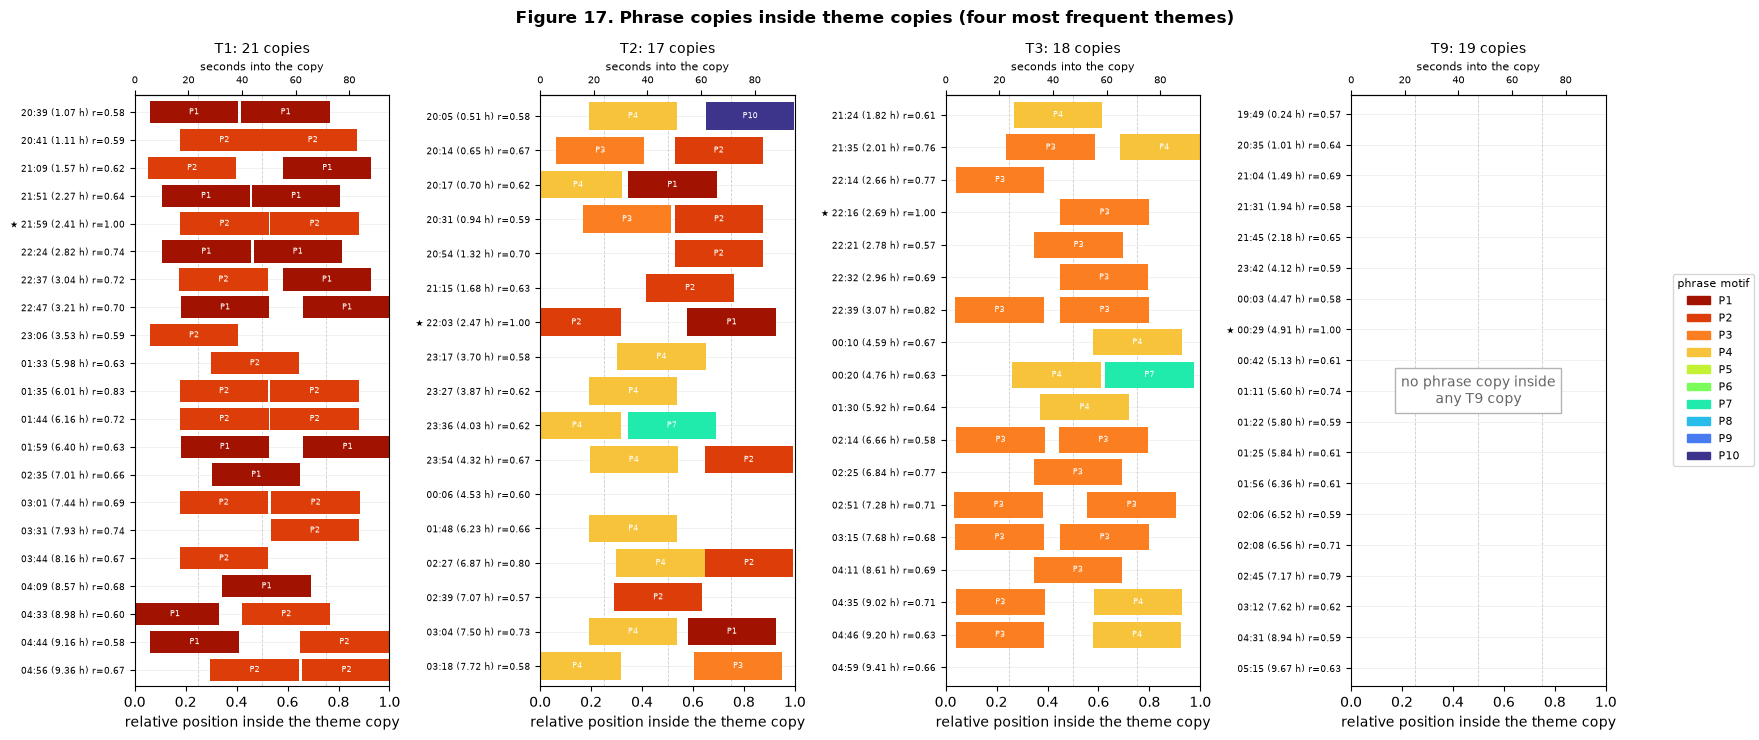

In [22]:
barcode("theme", "phrase", title="Figure 17. Phrase copies inside theme copies (four most frequent themes)",
        name="barcode_theme_phrase")

**Figure 17. Phrases inside themes.** A 95 s theme holds at most two 33 s phrase copies (they cannot overlap). In
T1 the two slots (~0.05–0.5 and ~0.5–0.95 of the theme) hold P1 or P2, often P1 then P1 or P2 then P2. T2 usually
holds P4 in its first half and P2 or P1 in its second. In T3 the first slot holds P3 and the second P3 or P4. Blocks
line up in the same slots from copy to copy. T9 (19 copies) has no phrase blocks at all: it is made of something
the top-10 phrase motifs do not capture.

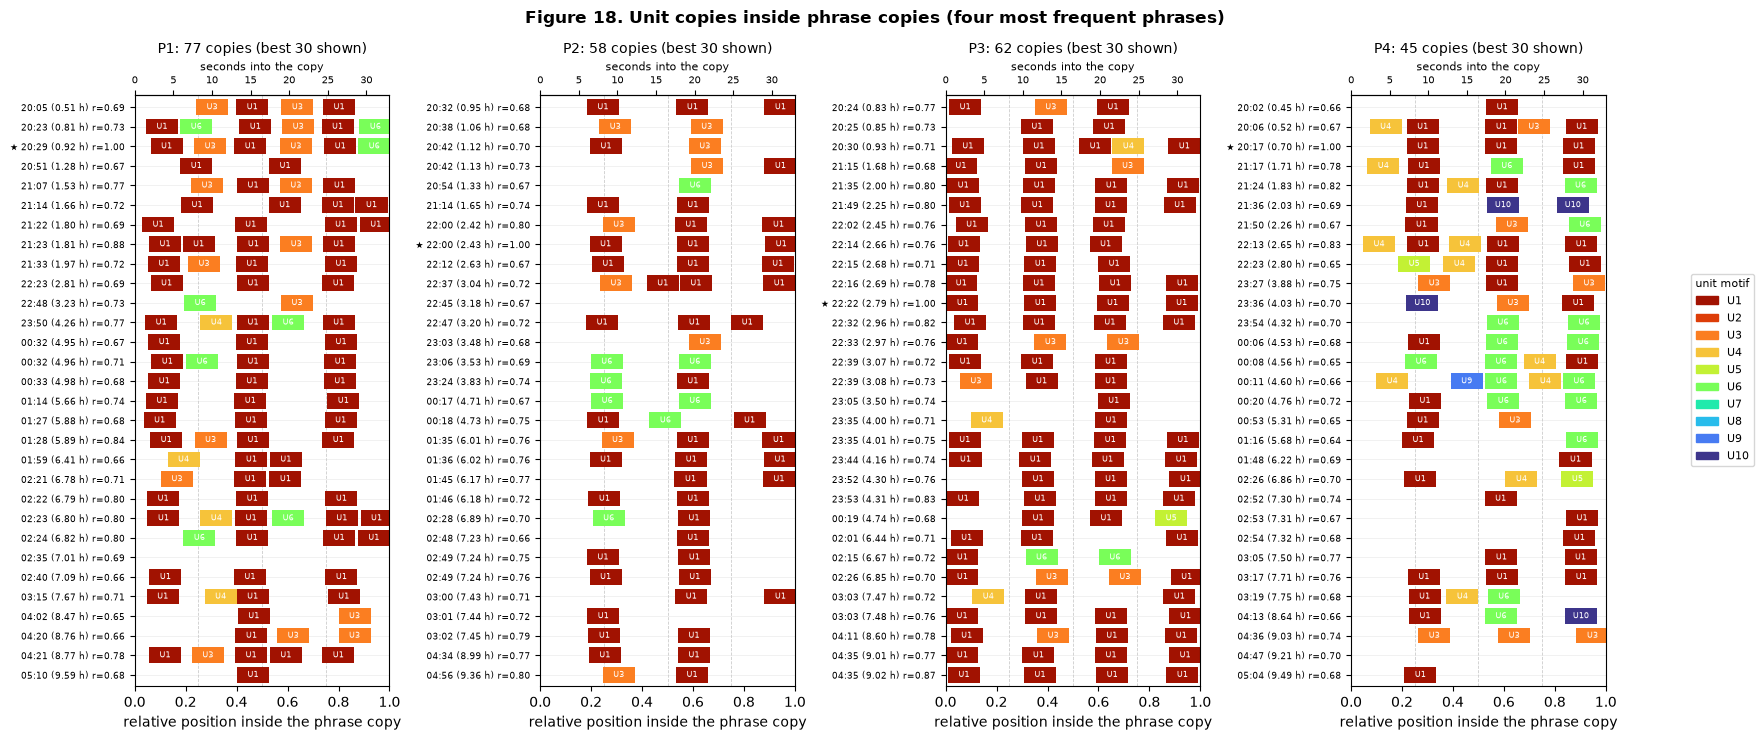

In [23]:
barcode("phrase", "unit", title="Figure 18. Unit copies inside phrase copies (four most frequent phrases)",
        name="barcode_phrase_unit")

**Figure 18. Units inside phrases.** The clearest nesting of all. P1 copies contain U1 at up to four fixed
positions about 7–8 s apart (~0.1, ~0.4, ~0.6 and ~0.85 of the phrase, i.e. ~3, 13, 20 and 28 s), so a P1 phrase
is essentially U1 sung four times with other sounds (often U3 or U6) in between. P2 contains U1 at ~0.2, ~0.5 and
~0.9; P3 at ~0.05, ~0.4, ~0.65 and ~0.9; P4 combines U1 at ~0.3, ~0.6 and ~0.85 with its own units U6 and U4. The
columns of blocks are straight from the top row to the bottom row, i.e. from the first to the last hour.

## 10-hour timeline, page by page

The whole night with **every copy of every motif**, readable copy by copy. The first page is a *page map*: the
whole night with one row per motif (S1–S2, T1–T10, P1–P10, U1–U10) and the page boundaries numbered. Each following
page covers **15 minutes** (40 pages). On each page:

- the thin top panel is c0 energy (10 s mean) with the whole-night 10th percentile as a dashed red line; grey
  shading marks quiet periods in both panels;
- below it, one row per motif, grouped by level (song, theme, phrase, unit; the level and length are written on
  the right, the motif and its total number of copies on the left);
- every copy is a rectangle at its true length; song and theme copies are labelled with their copy number and r
  (e.g. `c3 r=.64`), phrase copies with their copy number; the seed has a black outline and the label `seed`;
- dotted lines extend the start and end of every song, theme and phrase copy down through the lower rows, so a copy
  between two dotted lines of the same colour is **inside** that higher-level copy;
- black dashed lines mark the start and end of the original figure's window (01:11:15 and 02:26:15).

The pages are written to `reports/Motif_Hierarchy_Timeline.pdf` (vector, zoomable) and
`reports/figures/p3_timeline_XX.png`; the page map and one page are shown here.

In [24]:
ROWS = [(lvl, mi) for lvl in ORDER for mi in sorted(TOP[lvl]["motif"].unique())]
ROW_Y = {key: len(ROWS) - 1 - i for i, key in enumerate(ROWS)}
E_LIM = tuple(np.nanpercentile(ENERGY, [0.2, 99.9]))
PAGE_S = 900
N_PAGES = int(np.ceil(DURATION / PAGE_S))
LABEL_FS, ROW_FS = 6.5, 7.5


def draw_rows(ax, t0, t1, labels=True, guides=True):
    min_w = (t1 - t0) / 1500
    for k, lvl in enumerate(ORDER):
        ys = [ROW_Y[key] for key in ROWS if key[0] == lvl]
        ax.axhspan(min(ys) - 0.5, max(ys) + 0.5, color="0.97" if k % 2 else "w", zorder=0, lw=0)
        ax.axhline(min(ys) - 0.5, c="0.5", lw=0.6, zorder=1)
        ax.text(1.003, np.mean(ys), f"{lvl}\n{LEVELS[lvl]['length_s']:g} s", transform=ax.get_yaxis_transform(),
                va="center", ha="left", fontsize=8.5, fontweight="bold")
    for a, b in quiet_runs(t0, t1):
        ax.axvspan(a, b, color="0.86", lw=0, zorder=0.5)
    for lvl in ORDER:
        let = LETTER[lvl]
        for _, c in in_view(TOP[lvl], t0, t1).iterrows():
            mi, a, L = int(c["motif"]), c["start_s"], c["length_s"]
            y, col = ROW_Y[lvl, mi], COLORS[mi - 1]
            is_seed = c["r"] >= 0.9999
            ax.add_patch(Rectangle((a, y - 0.42), max(L, min_w), 0.84, fc=col, ec="k" if is_seed else "none",
                                   lw=0.8 if is_seed else 0, zorder=3))
            if guides and lvl != "unit":
                for edge in (a, a + L):
                    if t0 <= edge <= t1:
                        ax.plot([edge, edge], [y - 0.42, -0.5], ls=(0, (1, 1.5)), lw=0.45, c=col, zorder=2)
            if labels and lvl != "unit":
                vis0, vis1 = max(a, t0), min(a + L, t1)
                txt = "seed" if is_seed else (f"c{int(c['copy'])}" if lvl == "phrase" else
                                              f"c{int(c['copy'])} r={c['r']:.2f}".replace("0.", "."))
                if (vis1 - vis0) > (len(txt) + 1) * (t1 - t0) / 190:
                    ax.text((vis0 + vis1) / 2, y, txt, ha="center", va="center", fontsize=LABEL_FS,
                            color="w" if mi in (1, 2, 9, 10) else "k", zorder=4)
    for edge in IMAGE_WINDOW:
        if t0 <= edge <= t1:
            ax.axvline(edge, c="k", ls="--", lw=0.9, zorder=5)
    ax.set_yticks([ROW_Y[key] for key in ROWS])
    ax.set_yticklabels([f"{LETTER[l]}{mi} ({(TOP[l]['motif'] == mi).sum()})" for l, mi in ROWS], fontsize=ROW_FS)
    ax.tick_params(axis="y", length=0, pad=2)
    ax.set_ylim(-0.5, len(ROWS) - 0.5)
    ax.set_xlim(t0, t1)


def draw_energy(ax, t0, t1):
    e0, e1 = int(t0), int(min(t1, len(ENERGY)))
    for a, b in quiet_runs(t0, t1):
        ax.axvspan(a, b, color="0.86", lw=0)
    ax.plot(np.arange(e0, e1), ENERGY[e0:e1], c="k", lw=0.5)
    ax.axhline(QUIET, c="r", ls="--", lw=0.6)
    for edge in IMAGE_WINDOW:
        if t0 <= edge <= t1:
            ax.axvline(edge, c="k", ls="--", lw=0.9)
            ax.text(edge, E_LIM[1], (" start" if edge == IMAGE_WINDOW[0] else " end") + " of original figure window",
                    fontsize=8, va="top", ha="left")
    ax.set_xlim(t0, t1)
    ax.set_ylim(*E_LIM)
    ax.set_yticks([])
    ax.set_xticks([])
    ax.set_ylabel("c0\nenergy", fontsize=7.5, rotation=0, ha="right", va="center")


FOOTER = ("S = song (600 s), T = theme (95 s), P = phrase (33 s), U = unit (4.15 s); number in brackets = copies of "
          "that motif over the night. Label 'c3 r=.64' = 3rd copy in time order, correlation 0.64 with the seed. "
          "Black outline = seed. Dotted lines = start/end of song, theme and phrase copies (nesting guides). "
          "Grey = quiet (c0 10 s mean below the whole-night 10th percentile, red dashed line).")


def timeline_page(page):
    t0 = (page - 1) * PAGE_S
    t1 = min(t0 + PAGE_S, DURATION)
    fig = plt.figure(figsize=(11.69, 8.27))
    gs = fig.add_gridspec(2, 1, height_ratios=[0.9, 8], left=0.075, right=0.925, top=0.9, bottom=0.12, hspace=0.03)
    counts = []
    for lvl in ORDER:
        tab = TOP[lvl]
        counts.append(f"{LETTER[lvl]} {int(((tab['start_s'] >= t0) & (tab['start_s'] < t1)).sum())}")
    fig.text(0.075, 0.975, f"10-hour timeline, page {page} of {N_PAGES}: {clock(t0, '%H:%M')}–"
             f"{clock(t0 + PAGE_S, '%H:%M')} ({t0 / 3600:.2f}–{(t0 + PAGE_S) / 3600:.2f} h since 19:35:00)",
             fontsize=14, fontweight="bold", va="top")
    fig.text(0.075, 0.94, "copies starting on this page: " + ", ".join(counts) +
             "     |     SOCAL_H_76_230426_193500_df100.x.x.wav, MFCC c1 motifs", fontsize=9, va="top")
    ax_e, ax = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])
    draw_energy(ax_e, t0, t0 + PAGE_S)
    draw_rows(ax, t0, t1)
    ax.set_xlim(t0, t0 + PAGE_S)
    major = clock_ticks(t0, t0 + PAGE_S, 60)
    ax.set_xticks(major, labels=[clock(x) for x in major], fontsize=8.5)
    ax.set_xticks(clock_ticks(t0, t0 + PAGE_S, 10), minor=True)
    ax.tick_params(axis="x", which="both", pad=2)
    ax.grid(axis="x", which="major", c="0.8", lw=0.4, zorder=0)
    ax.set_xlabel("clock time (file timestamp); minor ticks every 10 s", fontsize=8.5)
    fig.text(0.075, 0.015, FOOTER, fontsize=8, va="bottom", wrap=True)
    return fig


def page_map():
    fig = plt.figure(figsize=(11.69, 8.27))
    gs = fig.add_gridspec(2, 1, height_ratios=[0.8, 5], left=0.075, right=0.935, top=0.85, bottom=0.17, hspace=0.05)
    ax_e, ax = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])
    draw_energy(ax_e, 0, DURATION)
    for txt in ax_e.texts:
        txt.set_visible(False)
    draw_rows(ax, 0, DURATION, labels=False, guides=False)
    for p in range(N_PAGES + 1):
        for a in (ax, ax_e):
            a.axvline(p * PAGE_S, c="0.3", lw=0.4, zorder=6)
        if p < N_PAGES:
            ax_e.text((p + 0.5) * PAGE_S, E_LIM[1], str(p + 1), ha="center", va="bottom", fontsize=6.5,
                      fontweight="bold")
    ticks = np.arange(0, DURATION + 1, 3600)
    ax.set_xticks(ticks, labels=[f"{x / 3600:.0f} h\n{clock(x)}" for x in ticks], fontsize=8.5)
    ax.set_xlabel("time since 19:35:00 (h) and clock time", fontsize=9)
    fig.text(0.075, 0.965, "10-hour timeline: page map", fontsize=14, fontweight="bold", va="top")
    fig.text(0.075, 0.93, "Every copy of every motif over the whole night (rows = motifs, grouped by level). "
             "Bold numbers above the energy strip = page numbers; each page covers 15 minutes.\n"
             "Black dashed lines = original figure window (011115+014845, 01:11:15–02:26:15).", fontsize=9,
             va="top")
    fig.text(0.075, 0.015, FOOTER, fontsize=8, va="bottom", wrap=True)
    return fig


pdf_path = os.path.join("reports", "Motif_Hierarchy_Timeline.pdf")
with PdfPages(pdf_path) as pdf:
    for page in range(N_PAGES + 1):
        fig = page_map() if page == 0 else timeline_page(page)
        pdf.savefig(fig)
        fig.savefig(os.path.join(FIG_DIR, f"p3_timeline_{page:02d}.png"), dpi=160)
        plt.close(fig)
print(f"{N_PAGES} timeline pages + page map -> {pdf_path} ({os.path.getsize(pdf_path) / 1e6:.1f} MB)")

40 timeline pages + page map -> reports\Motif_Hierarchy_Timeline.pdf (0.8 MB)


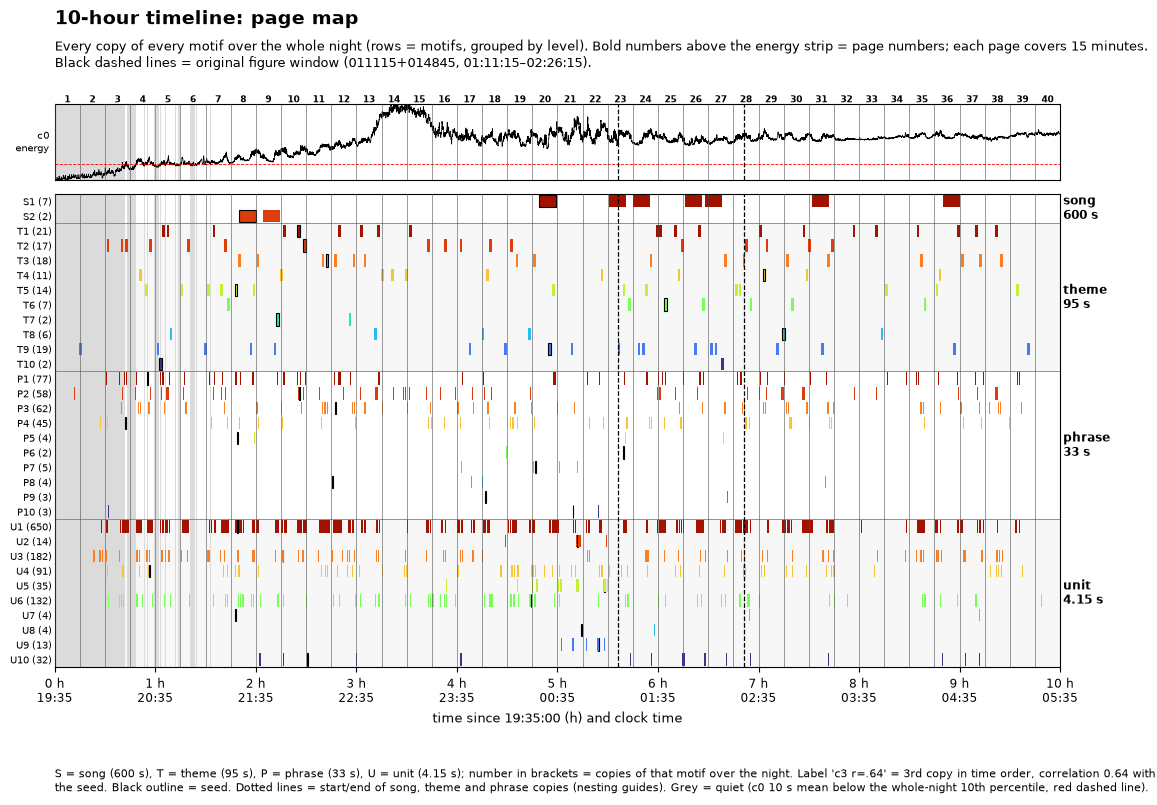

In [25]:
fig = page_map()
plt.show()

**Figure 19. Page map of the 10-hour timeline.** Every row is one motif; every tick a copy. Long-lived motifs (U1,
U3, U4, U6, P1–P4, T1–T5, T9) form near-continuous lines across the night once singing starts (~0.4 h), while
U2, U5, U9, P6, P7 are confined to the middle of the night (pages 12–28). The page numbers on top locate any time
in the detailed pages that follow.

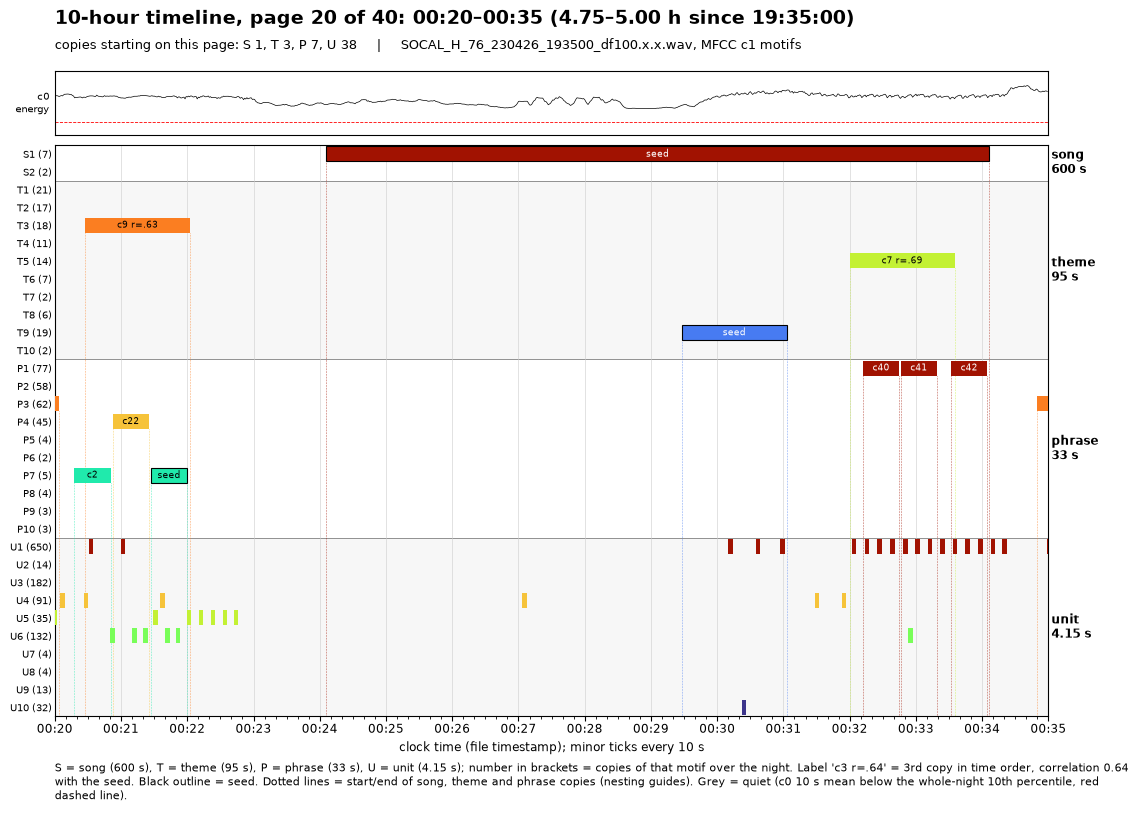

page 20 shown (contains the first copy of S1)


In [26]:
song1_page = int(song1["start_s"] // PAGE_S) + 1
fig = timeline_page(song1_page)
plt.show()
print(f"page {song1_page} shown (contains the first copy of S1)")

**Figure 20. One timeline page (page 20, 00:20–00:35, which holds the S1 seed).** Read down from a song or theme
copy: the dotted guides of the same colour bracket the phrase and unit copies inside it. At the start of the page,
T3 (copy 9) sits over P4 copy 22 and the P7 seed. The S1 seed (00:24–00:34) contains the T9 seed with U1 copies but
no phrase, then T5 (copy 7) over three back-to-back P1 copies (40–42), each filled with U1 copies: the multi-level
structure the test above quantifies, on one page.

## Discussion

**Motifs found.** With the null threshold, units give 10 motifs with 4–650 copies (1,157 in total; unit 1 alone has
650), phrases 10 motifs with 2–77 copies, themes 10 motifs with 2–21 copies, and songs only **2 motifs with 7 and 2
copies**. Ten-minute stretches rarely correlate above the null level, so the song level is thin. In the 5-minute
zoom (Figure 3), unit 1 recurs every ~7–12 s, the phrase rhythm found in Phase 1.

**The lower levels nest as the hypothesis says.** Compared with shifting all lower-level copies by a random offset
(Table 3, Figure 14):

| pair | contains (real vs null) | inside (real vs null) | consistency (real vs null) | p |
|---|---|---|---|---|
| theme ⊃ phrase | 76% vs 39% | 53% vs 22% | 0.39 vs 0.04 | ≤ 0.004 |
| phrase ⊃ unit | 94% vs 43% | 60% vs 22% | 0.43 vs 0.06 | 0.002 |
| theme ⊃ unit | 87% vs 57% | 58% vs 30% | 0.35 vs 0.11 | ≤ 0.004 |

Not only do lower-level copies sit inside higher-level copies far more often than chance, copies of the same higher
motif contain the *same* lower motifs (consistency 6–10× the null). The barcodes make this visible:

- every copy of **phrase motif 1** (77 copies) contains unit 1 at the same four positions (about 7–8 s apart), and
  phrase motif 2 contains unit 1 at ~0.2, ~0.5 and ~0.9 of its length (Figure 18);
- copies of **theme motif 1** contain phrase 1 or phrase 2 in the same two slots (~0.05–0.4 and ~0.4–0.9 of its
  length); theme 3 contains phrase 3 in its first slot and phrase 3 or 4 in its second (Figure 17).

**Song ⊃ theme: partly.** All song copies contain themes, but so would random positions (themes cover 31% of the
night; containment p = 0.27). The *consistency* is significant, though (0.56 vs 0.13, p = 0.006): every copy of song
motif 1 contains theme 9 at ~55–70% of its length, followed by theme 5 or theme 1 at ~80–95% (Figure 16). With only
9 song copies this is suggestive rather than conclusive.

**Song ⊃ phrase: no.** Phrase copies are *less* often inside song copies than chance (8% vs 14%). Song motif 1
is built mainly on theme 9, and theme 9's 19 copies contain no phrase copies at all (Figure 15b): whatever theme 9 is
made of, it is not one of the top-10 phrase motifs. The chain song → theme → phrase therefore breaks at theme 9,
while it holds for themes 1–5 and the phrases and units inside them.

**Verdict.** The hierarchy *unit ⊂ phrase ⊂ theme* is strongly supported. The top level (theme ⊂ song) shows a
consistent arrangement of themes inside songs, but rests on 9 song copies and on a theme (9) that does not decompose
into the phrase motifs found here.

**Caveats and next steps.**

- The levels use single lengths (4.15, 33, 95, 600 s); a 33 s phrase motif can only hold 2 copies inside a 95 s
  theme, and the true phrase may be shorter (Phase 1 found an ~11 s period).
- At 600 s, z-normalized correlation is dominated by slow loudness changes; detrending c1 or using a slightly lower
  threshold would give more song copies and a stronger test.
- Units are analysed at 20 Hz, so very short units (< 0.5 s) are smoothed out.
- Theme 9 deserves a closer look (e.g. its own phrase-level search with a shorter phrase length).